In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import os
import glob
import matplotlib.pyplot as plt

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Xarray:", xr.__version__)

print("Libraries imported successfully.")

NumPy: 2.1.3
Pandas: 2.2.3
Xarray: 2025.12.0
Libraries imported successfully.


In [2]:
from pathlib import Path

# Update this path to your project directory
PROJECT_DIR = Path(r"D:\SVKM NMIMS Indore\Academic Related\Research Papers\Spatiotemporal GNN\New Code Setup\Spatiotemporal_GNN_Revised")

RAINFALL_DIR = PROJECT_DIR / "data" / "raw" / "rainfall"
INTERMEDIATE_DIR = PROJECT_DIR / "data" / "intermediate"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

# Check directories
print("Project directory exists:", PROJECT_DIR.exists())
print("Rainfall directory exists:", RAINFALL_DIR.exists())

# List rainfall NetCDF files
rainfall_files = sorted(RAINFALL_DIR.glob("*.nc"))

print("\nTotal rainfall NetCDF files:", len(rainfall_files))

for file in rainfall_files:
    print(file.name)

Project directory exists: True
Rainfall directory exists: True

Total rainfall NetCDF files: 26
RF25_ind2000_rfp25.nc
RF25_ind2001_rfp25.nc
RF25_ind2002_rfp25.nc
RF25_ind2003_rfp25.nc
RF25_ind2004_rfp25.nc
RF25_ind2005_rfp25.nc
RF25_ind2006_rfp25.nc
RF25_ind2007_rfp25.nc
RF25_ind2008_rfp25.nc
RF25_ind2009_rfp25.nc
RF25_ind2010_rfp25.nc
RF25_ind2011_rfp25.nc
RF25_ind2012_rfp25.nc
RF25_ind2013_rfp25.nc
RF25_ind2014_rfp25.nc
RF25_ind2015_rfp25.nc
RF25_ind2016_rfp25.nc
RF25_ind2017_rfp25.nc
RF25_ind2018_rfp25.nc
RF25_ind2019_rfp25.nc
RF25_ind2020_rfp25.nc
RF25_ind2021_rfp25.nc
RF25_ind2022_rfp25.nc
RF25_ind2023_rfp25.nc
RF25_ind2024_rfp25.nc
RF25_ind2025_rfp25.nc


In [3]:
# Select the first rainfall file (year 2000)
sample_file = rainfall_files[0]

# Open the NetCDF dataset
ds = xr.open_dataset(sample_file)

print("File:", sample_file.name)

print("\n--- Dataset Structure ---")
print(ds)

print("\n--- Data Variables ---")
print(list(ds.data_vars))

print("\n--- Dimensions ---")
print(dict(ds.sizes))

print("\n--- Coordinate Variables ---")
print(list(ds.coords))

print("\n--- Global Attributes ---")
print(ds.attrs)

print("\n--- Variable Attributes ---")
for var in ds.data_vars:
    print(f"\n{var}:")
    print(ds[var].attrs)

ds.close()

File: RF25_ind2000_rfp25.nc

--- Dataset Structure ---
<xarray.Dataset> Size: 51MB
Dimensions:    (TIME: 366, LATITUDE: 129, LONGITUDE: 135)
Coordinates:
  * TIME       (TIME) datetime64[ns] 3kB 2000-01-01 2000-01-02 ... 2000-12-31
  * LATITUDE   (LATITUDE) float64 1kB 6.5 6.75 7.0 7.25 ... 38.0 38.25 38.5
  * LONGITUDE  (LONGITUDE) float64 1kB 66.5 66.75 67.0 ... 99.5 99.75 100.0
Data variables:
    RAINFALL   (TIME, LATITUDE, LONGITUDE) float64 51MB ...
Attributes:
    history:      FERRET V7.5 (optimized) 20-Jan-23
    Conventions:  CF-1.6

--- Data Variables ---
['RAINFALL']

--- Dimensions ---
{'TIME': 366, 'LATITUDE': 129, 'LONGITUDE': 135}

--- Coordinate Variables ---
['LONGITUDE', 'LATITUDE', 'TIME']

--- Global Attributes ---
{'history': 'FERRET V7.5 (optimized) 20-Jan-23', 'Conventions': 'CF-1.6'}

--- Variable Attributes ---

RAINFALL:
{'long_name': 'Rainfall', 'units': 'mm', 'history': 'From ind2000_rfp25.grd'}


In [4]:
# Reopen the sample dataset
ds = xr.open_dataset(sample_file)
rain = ds["RAINFALL"]

print("--- Rainfall Data Statistics ---")
print("Data type:", rain.dtype)
print("Minimum:", float(rain.min(skipna=True).values))
print("Maximum:", float(rain.max(skipna=True).values))
print("Mean:", float(rain.mean(skipna=True).values))
print("Standard deviation:", float(rain.std(skipna=True).values))

print("\n--- Missing and Valid Values ---")
total_values = rain.size
missing_values = int(rain.isnull().sum().values)
valid_values = total_values - missing_values

print("Total values:", total_values)
print("Valid values:", valid_values)
print("Missing values:", missing_values)
print("Missing percentage:", round(100 * missing_values / total_values, 4), "%")

print("\n--- Rainfall Value Checks ---")
print("Zero values:", int((rain == 0).sum().values))
print("Negative values:", int((rain < 0).sum().values))

print("\n--- Rainfall Quantiles ---")
print(rain.quantile([0, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 1.0], skipna=True).values)

print("\n--- NetCDF Variable Encoding ---")
print(rain.encoding)

print("\n--- Time Interval Check ---")
print("First date:", str(ds["TIME"].values[0]))
print("Last date:", str(ds["TIME"].values[-1]))
print("Number of unique time intervals:",
      len(np.unique(np.diff(ds["TIME"].values))))

ds.close()

--- Rainfall Data Statistics ---
Data type: float64
Minimum: 0.0
Maximum: 569.6158447265625
Mean: 2.7512857704307785
Standard deviation: 9.948969817628837

--- Missing and Valid Values ---
Total values: 6373890
Valid values: 1816824
Missing values: 4557066
Missing percentage: 71.4958 %

--- Rainfall Value Checks ---
Zero values: 1331794
Negative values: 0

--- Rainfall Quantiles ---
[0.00000000e+00 0.00000000e+00 0.00000000e+00 2.57947862e-01
 7.24226460e+00 1.62202572e+01 4.65846001e+01 5.69615845e+02]

--- NetCDF Variable Encoding ---
{'dtype': dtype('float64'), 'source': 'D:\\SVKM NMIMS Indore\\Academic Related\\Research Papers\\Spatiotemporal GNN\\New Code Setup\\Spatiotemporal_GNN_Revised\\data\\raw\\rainfall\\RF25_ind2000_rfp25.nc', 'original_shape': (366, 129, 135), 'missing_value': np.float64(-999.0), '_FillValue': np.float64(-999.0)}

--- Time Interval Check ---
First date: 2000-01-01T00:00:00.000000000
Last date: 2000-12-31T00:00:00.000000000
Number of unique time intervals: 

--- Spatial Missing Data Summary ---
Total spatial grid cells: 17415
Completely missing cells: 12451
Partially missing cells: 0
Cells with complete daily observations: 4964

--- Daily Spatial Coverage ---
Minimum valid cells per day: 4964
Median valid cells per day: 4964
Maximum valid cells per day: 4964

--- Daily Coverage Quantiles ---
[4964. 4964. 4964. 4964. 4964.]


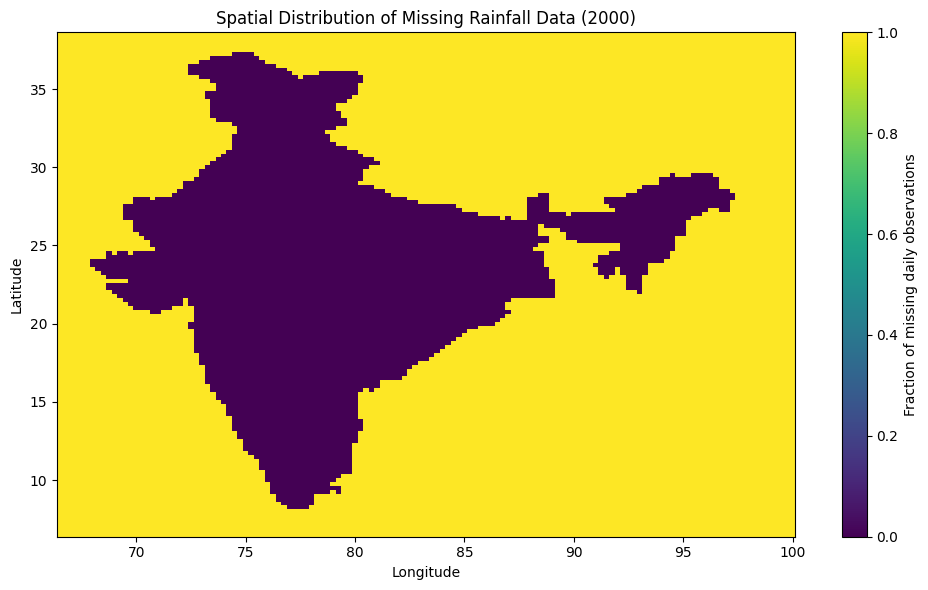

In [5]:
# Open the 2000 rainfall dataset
ds = xr.open_dataset(sample_file)
rain = ds["RAINFALL"]

# Missing fraction for each spatial grid cell across the year
missing_fraction = rain.isnull().mean(dim="TIME")

# Valid grid cells on each day
valid_cells_per_day = rain.notnull().sum(
    dim=["LATITUDE", "LONGITUDE"]
)

# Classify grid cells based on annual data availability
all_missing = int((missing_fraction == 1).sum().values)
partially_missing = int(
    ((missing_fraction > 0) & (missing_fraction < 1)).sum().values
)
complete = int((missing_fraction == 0).sum().values)

print("--- Spatial Missing Data Summary ---")
print("Total spatial grid cells:", missing_fraction.size)
print("Completely missing cells:", all_missing)
print("Partially missing cells:", partially_missing)
print("Cells with complete daily observations:", complete)

print("\n--- Daily Spatial Coverage ---")
print("Minimum valid cells per day:",
      int(valid_cells_per_day.min().values))
print("Median valid cells per day:",
      int(valid_cells_per_day.median().values))
print("Maximum valid cells per day:",
      int(valid_cells_per_day.max().values))

print("\n--- Daily Coverage Quantiles ---")
print(valid_cells_per_day.quantile(
    [0, 0.25, 0.50, 0.75, 1.0]
).values)

# Plot spatial missing-data distribution
plt.figure(figsize=(10, 6))

plt.pcolormesh(
    missing_fraction["LONGITUDE"].values,
    missing_fraction["LATITUDE"].values,
    missing_fraction.values,
    shading="auto",
    vmin=0,
    vmax=1,
    cmap="viridis"
)

plt.colorbar(label="Fraction of missing daily observations")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Spatial Distribution of Missing Rainfall Data (2000)")
plt.tight_layout()
plt.show()

ds.close()

In [6]:
# Load the existing spatial node coordinates
GRID_NODES_FILE = PROJECT_DIR / "data" / "spatial" / "grid_nodes.csv"

grid_nodes = pd.read_csv(GRID_NODES_FILE)

print("--- Grid Nodes File ---")
print("Shape:", grid_nodes.shape)

print("\nColumn names:")
print(grid_nodes.columns.tolist())

print("\nFirst 10 records:")
display(grid_nodes.head(10))

print("\nData types:")
print(grid_nodes.dtypes)

print("\nMissing values:")
print(grid_nodes.isnull().sum())

--- Grid Nodes File ---
Shape: (5040, 2)

Column names:
['latitude', 'longitude']

First 10 records:


,latitude,longitude
0,8.451258,76.834814
1,8.733465,76.608342
2,8.631885,76.770510
3,8.885523,76.547012
4,8.858651,76.733590
5,9.108651,76.733590
6,9.224103,76.354104
7,9.118985,76.503286
8,9.358651,76.483590
9,9.382370,76.326160



Data types:
latitude     float64
longitude    float64
dtype: object

Missing values:
latitude     0
longitude    0
dtype: int64


In [7]:
from sklearn.neighbors import BallTree

# Open rainfall data
ds = xr.open_dataset(sample_file)
rain = ds["RAINFALL"]

# Identify rainfall grid cells with valid observations
valid_mask = rain.notnull().any(dim="TIME")

lat_grid, lon_grid = np.meshgrid(
    ds["LATITUDE"].values,
    ds["LONGITUDE"].values,
    indexing="ij"
)

rain_coords = np.column_stack([
    lat_grid[valid_mask.values],
    lon_grid[valid_mask.values]
])

node_coords = grid_nodes[["latitude", "longitude"]].values

# Convert coordinates to radians
rain_rad = np.radians(rain_coords)
node_rad = np.radians(node_coords)

# Build spatial search tree
tree = BallTree(rain_rad, metric="haversine")

# Find nearest rainfall grid cell for every existing node
distances, indices = tree.query(node_rad, k=1)

# Convert distances from radians to kilometres
earth_radius_km = 6371.0
nearest_dist_km = distances[:, 0] * earth_radius_km

print("--- Coordinate Comparison ---")
print("Existing spatial nodes:", len(node_coords))
print("Valid rainfall grid cells:", len(rain_coords))

print("\n--- Nearest Rainfall Grid Distance (km) ---")
print("Minimum:", round(nearest_dist_km.min(), 3))
print("Mean:", round(nearest_dist_km.mean(), 3))
print("Median:", round(np.median(nearest_dist_km), 3))
print("95th percentile:", round(np.percentile(nearest_dist_km, 95), 3))
print("Maximum:", round(nearest_dist_km.max(), 3))

print("\n--- Distance Distribution ---")
for threshold in [5, 10, 15, 20, 25, 30, 40]:
    count = int((nearest_dist_km <= threshold).sum())
    print(f"Within {threshold:2d} km: {count} nodes")

# Identify nodes with the largest nearest-neighbour distances
distance_report = grid_nodes.copy()
distance_report["nearest_rainfall_distance_km"] = nearest_dist_km

print("\n--- 15 Nodes with Largest Distances ---")
display(
    distance_report.nlargest(
        15, "nearest_rainfall_distance_km"
    )
)

ds.close()

--- Coordinate Comparison ---
Existing spatial nodes: 5040
Valid rainfall grid cells: 4964

--- Nearest Rainfall Grid Distance (km) ---
Minimum: 0.423
Mean: 18.748
Median: 12.197
95th percentile: 13.223
Maximum: 1632.982

--- Distance Distribution ---
Within  5 km: 44 nodes
Within 10 km: 204 nodes
Within 15 km: 4889 nodes
Within 20 km: 4973 nodes
Within 25 km: 4998 nodes
Within 30 km: 5001 nodes
Within 40 km: 5008 nodes

--- 15 Nodes with Largest Distances ---


,latitude,longitude,nearest_rainfall_distance_km
3852,6.880740,94.151530,1632.981557
3855,7.057984,94.149049,1627.629993
3853,6.895961,94.050953,1621.825533
3854,7.066003,94.024939,1614.154953
3850,9.173042,92.951590,1402.696677
3851,9.240889,92.956195,1396.432512
3857,10.632691,92.670611,1248.094495
3856,10.629388,92.579049,1243.029849
3859,10.798196,92.666766,1232.413354
3858,10.775226,92.580181,1229.419417


In [8]:
# Identify nodes with nearest rainfall grid distance > 40 km
distant_nodes = distance_report[
    distance_report["nearest_rainfall_distance_km"] > 40
].copy()

print("Total distant nodes:", len(distant_nodes))

print("\n--- All Distant Nodes ---")
display(
    distant_nodes.sort_values(
        "nearest_rainfall_distance_km",
        ascending=False
    )
)

print("\n--- Distance Summary ---")
print(
    distant_nodes["nearest_rainfall_distance_km"].describe()
)

print("\n--- Geographical Range ---")
print(
    distant_nodes[
        ["latitude", "longitude"]
    ].agg(["min", "max"])
)

Total distant nodes: 32

--- All Distant Nodes ---


,latitude,longitude,nearest_rainfall_distance_km
3852,6.880740,94.151530,1632.981557
3855,7.057984,94.149049,1627.629993
3853,6.895961,94.050953,1621.825533
3854,7.066003,94.024939,1614.154953
3850,9.173042,92.951590,1402.696677
3851,9.240889,92.956195,1396.432512
3857,10.632691,92.670611,1248.094495
3856,10.629388,92.579049,1243.029849
3859,10.798196,92.666766,1232.413354
3858,10.775226,92.580181,1229.419417



--- Distance Summary ---
count      32.000000
mean     1050.060942
std       381.182442
min       303.363786
25%       960.594510
50%      1084.076574
75%      1235.067478
max      1632.981557
Name: nearest_rainfall_distance_km, dtype: float64

--- Geographical Range ---
      latitude  longitude
min   6.880740  71.699313
max  13.533281  94.151530


In [10]:
import re

rainfall_coverage = []
mask_comparison = []

reference_mask = None

for file in rainfall_files:

    ds = xr.open_dataset(file)
    rain = ds["RAINFALL"]

    # Identify grid cells with valid observations
    current_mask = rain.notnull().any(dim="TIME")

    valid_cells = int(current_mask.sum().values)
    total_cells = current_mask.size
    missing_cells = total_cells - valid_cells

    # Extract year reliably from filename
    match = re.search(r"ind(\d{4})", file.stem)

    if match is None:
        raise ValueError(f"Year not found in filename: {file.name}")

    year = int(match.group(1))

    rainfall_coverage.append({
        "year": year,
        "valid_cells": valid_cells,
        "missing_cells": missing_cells,
        "total_cells": total_cells
    })

    # Compare spatial masks
    if reference_mask is None:
        reference_mask = current_mask.values.copy()

        different = 0
    else:
        different = int(
            np.sum(current_mask.values != reference_mask)
        )

    mask_comparison.append({
        "year": year,
        "different_cells": different
    })

    ds.close()

coverage_df = pd.DataFrame(rainfall_coverage)
mask_df = pd.DataFrame(mask_comparison)

print("--- Annual Rainfall Spatial Coverage ---")
display(coverage_df)

print("\n--- Spatial Mask Consistency ---")
display(mask_df)

print("\nAll years have identical spatial masks:",
      mask_df["different_cells"].sum() == 0)

--- Annual Rainfall Spatial Coverage ---


,year,valid_cells,missing_cells,total_cells
0,2000,4964,12451,17415
1,2001,4964,12451,17415
2,2002,4964,12451,17415
3,2003,4964,12451,17415
4,2004,4964,12451,17415
5,2005,4964,12451,17415
6,2006,4964,12451,17415
7,2007,4964,12451,17415
8,2008,4964,12451,17415
9,2009,4964,12451,17415



--- Spatial Mask Consistency ---


,year,different_cells
0,2000,0
1,2001,0
2,2002,0
3,2003,0
4,2004,0
5,2005,0
6,2006,0
7,2007,0
8,2008,0
9,2009,0



All years have identical spatial masks: True


In [11]:
# Create a separate coverage report
node_coverage = grid_nodes.copy()

node_coverage["nearest_rainfall_distance_km"] = nearest_dist_km

# Preliminary flag, not a final exclusion decision
node_coverage["coverage_status"] = np.where(
    node_coverage["nearest_rainfall_distance_km"] > 40,
    "Requires investigation",
    "Within 40 km"
)

# Save the report
coverage_file = (
    PROJECT_DIR / "data" / "spatial"
    / "rainfall_node_coverage.csv"
)

node_coverage.to_csv(coverage_file, index=False)

print("--- Node Coverage Report ---")
print("Total nodes:", len(node_coverage))
print("\nCoverage classification:")
print(node_coverage["coverage_status"].value_counts())

print("\nReport saved at:")
print(coverage_file)

print("\n--- Nodes Requiring Investigation ---")
display(
    node_coverage[
        node_coverage["coverage_status"]
        == "Requires investigation"
    ].sort_values(
        "nearest_rainfall_distance_km",
        ascending=False
    )
)

--- Node Coverage Report ---
Total nodes: 5040

Coverage classification:
coverage_status
Within 40 km              5008
Requires investigation      32
Name: count, dtype: int64

Report saved at:
D:\SVKM NMIMS Indore\Academic Related\Research Papers\Spatiotemporal GNN\New Code Setup\Spatiotemporal_GNN_Revised\data\spatial\rainfall_node_coverage.csv

--- Nodes Requiring Investigation ---


,latitude,longitude,nearest_rainfall_distance_km,coverage_status
3852,6.880740,94.151530,1632.981557,Requires investigation
3855,7.057984,94.149049,1627.629993,Requires investigation
3853,6.895961,94.050953,1621.825533,Requires investigation
3854,7.066003,94.024939,1614.154953,Requires investigation
3850,9.173042,92.951590,1402.696677,Requires investigation
3851,9.240889,92.956195,1396.432512,Requires investigation
3857,10.632691,92.670611,1248.094495,Requires investigation
3856,10.629388,92.579049,1243.029849,Requires investigation
3859,10.798196,92.666766,1232.413354,Requires investigation
3858,10.775226,92.580181,1229.419417,Requires investigation


In [12]:
TEMPERATURE_DIR = PROJECT_DIR / "data" / "raw" / "temperature"

temperature_files = sorted(
    TEMPERATURE_DIR.glob("*.nc")
)

temperature_grd_files = sorted(
    TEMPERATURE_DIR.glob("*.GRD")
)

print("--- Temperature File Inventory ---")

print("\nNetCDF files:", len(temperature_files))

for file in temperature_files:
    print(file.name)

print("\nGRD files:", len(temperature_grd_files))

for file in temperature_grd_files:
    print(file.name)

--- Temperature File Inventory ---

NetCDF files: 24
Maxtemp_MaxT_2000.nc
Maxtemp_MaxT_2001.nc
Maxtemp_MaxT_2002.nc
Maxtemp_MaxT_2003.nc
Maxtemp_MaxT_2004.nc
Maxtemp_MaxT_2005.nc
Maxtemp_MaxT_2006.nc
Maxtemp_MaxT_2007.nc
Maxtemp_MaxT_2008.nc
Maxtemp_MaxT_2009.nc
Maxtemp_MaxT_2010.nc
Maxtemp_MaxT_2011.nc
Maxtemp_MaxT_2012.nc
Maxtemp_MaxT_2013.nc
Maxtemp_MaxT_2014.nc
Maxtemp_MaxT_2015.nc
Maxtemp_MaxT_2016.nc
Maxtemp_MaxT_2017.nc
Maxtemp_MaxT_2018.nc
Maxtemp_MaxT_2019.nc
Maxtemp_MaxT_2020.nc
Maxtemp_MaxT_2021.nc
Maxtemp_MaxT_2022.nc
Maxtemp_MaxT_2023.nc

GRD files: 2
Maxtemp_MaxT_2024.GRD
Maxtemp_MaxT_2025.GRD


In [13]:
# Select the first temperature NetCDF file
sample_temp_file = temperature_files[0]

# Open dataset
ds_temp = xr.open_dataset(sample_temp_file)

print("File:", sample_temp_file.name)

print("\n--- Dataset Structure ---")
print(ds_temp)

print("\n--- Data Variables ---")
print(list(ds_temp.data_vars))

print("\n--- Dimensions ---")
print(dict(ds_temp.sizes))

print("\n--- Coordinate Variables ---")
print(list(ds_temp.coords))

print("\n--- Global Attributes ---")
print(ds_temp.attrs)

print("\n--- Variable Attributes ---")
for var in ds_temp.data_vars:
    print(f"\n{var}:")
    print(ds_temp[var].attrs)

ds_temp.close()

File: Maxtemp_MaxT_2000.nc

--- Dataset Structure ---
<xarray.Dataset> Size: 1MB
Dimensions:      (time: 366, lat: 31, lon: 31)
Coordinates:
  * time         (time) datetime64[ns] 3kB 2023-01-01 2023-01-02 ... 2024-01-01
  * lat          (lat) float64 248B 7.5 8.5 9.5 10.5 ... 34.5 35.5 36.5 37.5
  * lon          (lon) float64 248B 67.5 68.5 69.5 70.5 ... 94.5 95.5 96.5 97.5
Data variables:
    temperature  (time, lat, lon) float32 1MB ...
Attributes:
    description:  IMD 1°x1° Maximum Temperature Data from Maxtemp_MaxT_2000.GRD
    units:        °C

--- Data Variables ---
['temperature']

--- Dimensions ---
{'time': 366, 'lat': 31, 'lon': 31}

--- Coordinate Variables ---
['time', 'lat', 'lon']

--- Global Attributes ---
{'description': 'IMD 1°x1° Maximum Temperature Data from Maxtemp_MaxT_2000.GRD', 'units': '°C'}

--- Variable Attributes ---

temperature:
{}


In [14]:
temperature_time_report = []

for file in temperature_files:
    ds = xr.open_dataset(file)
    temp = ds["temperature"]

    temperature_time_report.append({
        "filename": file.name,
        "expected_year": int(file.stem[-4:]),
        "observations": temp.sizes["time"],
        "first_date": str(pd.Timestamp(ds.time.values[0]).date()),
        "last_date": str(pd.Timestamp(ds.time.values[-1]).date()),
        "lat_min": float(ds.lat.min()),
        "lat_max": float(ds.lat.max()),
        "lon_min": float(ds.lon.min()),
        "lon_max": float(ds.lon.max())
    })

    ds.close()

temperature_time_df = pd.DataFrame(temperature_time_report)

display(temperature_time_df)

,filename,expected_year,observations,first_date,last_date,lat_min,lat_max,lon_min,lon_max
0,Maxtemp_MaxT_2000.nc,2000,366,2023-01-01,2024-01-01,7.5,37.5,67.5,97.5
1,Maxtemp_MaxT_2001.nc,2001,365,2023-01-01,2023-12-31,7.5,37.5,67.5,97.5
2,Maxtemp_MaxT_2002.nc,2002,365,2023-01-01,2023-12-31,7.5,37.5,67.5,97.5
3,Maxtemp_MaxT_2003.nc,2003,365,2023-01-01,2023-12-31,7.5,37.5,67.5,97.5
4,Maxtemp_MaxT_2004.nc,2004,366,2023-01-01,2024-01-01,7.5,37.5,67.5,97.5
5,Maxtemp_MaxT_2005.nc,2005,365,2023-01-01,2023-12-31,7.5,37.5,67.5,97.5
6,Maxtemp_MaxT_2006.nc,2006,365,2023-01-01,2023-12-31,7.5,37.5,67.5,97.5
7,Maxtemp_MaxT_2007.nc,2007,365,2023-01-01,2023-12-31,7.5,37.5,67.5,97.5
8,Maxtemp_MaxT_2008.nc,2008,366,2023-01-01,2024-01-01,7.5,37.5,67.5,97.5
9,Maxtemp_MaxT_2009.nc,2009,365,2023-01-01,2023-12-31,7.5,37.5,67.5,97.5


In [15]:
temperature_stats = []
temperature_arrays = {}

for file in temperature_files:
    ds = xr.open_dataset(file)
    temp = ds["temperature"].values

    valid = temp[np.isfinite(temp)]

    temperature_stats.append({
        "filename": file.name,
        "valid_values": len(valid),
        "missing_values": int(np.isnan(temp).sum()),
        "minimum": float(np.min(valid)) if len(valid) else np.nan,
        "maximum": float(np.max(valid)) if len(valid) else np.nan,
        "mean": float(np.mean(valid)) if len(valid) else np.nan,
        "std": float(np.std(valid)) if len(valid) else np.nan
    })

    temperature_arrays[file.name] = temp.copy()
    ds.close()

temperature_stats_df = pd.DataFrame(temperature_stats)

display(temperature_stats_df.round(3))

# Compare actual temperature arrays
reference_name = temperature_files[0].name
reference_array = temperature_arrays[reference_name]

print("\n--- Comparison with 2000 file ---")

for file in temperature_files[1:]:
    current_array = temperature_arrays[file.name]

    if current_array.shape == reference_array.shape:
        identical = np.array_equal(
            current_array, reference_array, equal_nan=True
        )
        difference = np.nanmean(
            np.abs(current_array - reference_array)
        )

        print(
            file.name,
            "| Identical:", identical,
            "| Mean absolute difference:", round(float(difference), 4)
        )
    else:
        print(file.name, "| Different shape:", current_array.shape)

,filename,valid_values,missing_values,minimum,maximum,mean,std
0,Maxtemp_MaxT_2000.nc,128389,223337,0.620,45.000,30.669,5.748
1,Maxtemp_MaxT_2001.nc,128749,222016,1.700,46.190,30.770,5.421
2,Maxtemp_MaxT_2002.nc,128416,222349,-0.080,46.320,31.125,5.927
3,Maxtemp_MaxT_2003.nc,130443,220322,2.110,46.900,30.573,6.232
4,Maxtemp_MaxT_2004.nc,129273,222453,0.280,45.700,30.799,5.900
5,Maxtemp_MaxT_2005.nc,128990,221775,0.220,47.030,30.634,6.173
6,Maxtemp_MaxT_2006.nc,131334,219431,0.530,45.710,30.909,5.519
7,Maxtemp_MaxT_2007.nc,129896,220869,1.340,46.080,30.764,5.738
8,Maxtemp_MaxT_2008.nc,129800,221926,-1.190,44.400,30.633,5.690
9,Maxtemp_MaxT_2009.nc,127866,222899,5.740,45.890,31.550,5.722



--- Comparison with 2000 file ---
Maxtemp_MaxT_2001.nc | Different shape: (365, 31, 31)
Maxtemp_MaxT_2002.nc | Different shape: (365, 31, 31)
Maxtemp_MaxT_2003.nc | Different shape: (365, 31, 31)
Maxtemp_MaxT_2004.nc | Identical: False | Mean absolute difference: 2.3483
Maxtemp_MaxT_2005.nc | Different shape: (365, 31, 31)
Maxtemp_MaxT_2006.nc | Different shape: (365, 31, 31)
Maxtemp_MaxT_2007.nc | Different shape: (365, 31, 31)
Maxtemp_MaxT_2008.nc | Identical: False | Mean absolute difference: 2.1221
Maxtemp_MaxT_2009.nc | Different shape: (365, 31, 31)
Maxtemp_MaxT_2010.nc | Different shape: (365, 31, 31)
Maxtemp_MaxT_2011.nc | Different shape: (365, 31, 31)
Maxtemp_MaxT_2012.nc | Identical: False | Mean absolute difference: 2.2425
Maxtemp_MaxT_2013.nc | Different shape: (365, 31, 31)
Maxtemp_MaxT_2014.nc | Different shape: (365, 31, 31)
Maxtemp_MaxT_2015.nc | Different shape: (365, 31, 31)
Maxtemp_MaxT_2016.nc | Identical: False | Mean absolute difference: 2.2126
Maxtemp_MaxT_2017

In [16]:
# Inspect metadata from the 2000 temperature file
ds = xr.open_dataset(temperature_files[0])

print("--- Time Coordinate Attributes ---")
print(ds["time"].attrs)

print("\n--- Time Coordinate Encoding ---")
print(ds["time"].encoding)

print("\n--- Temperature Variable Encoding ---")
print(ds["temperature"].encoding)

print("\n--- First 10 Temperature Dates ---")
print(ds["time"].values[:10])

print("\n--- Last 10 Temperature Dates ---")
print(ds["time"].values[-10:])

print("\n--- First 10 Daily Mean Temperatures ---")
daily_mean = ds["temperature"].mean(dim=["lat", "lon"], skipna=True)
print(daily_mean.values[:10])

ds.close()

--- Time Coordinate Attributes ---
{}

--- Time Coordinate Encoding ---
{'dtype': dtype('int64'), 'zlib': False, 'szip': False, 'zstd': False, 'bzip2': False, 'blosc': False, 'shuffle': False, 'complevel': 0, 'fletcher32': False, 'contiguous': True, 'chunksizes': None, 'source': 'D:\\SVKM NMIMS Indore\\Academic Related\\Research Papers\\Spatiotemporal GNN\\New Code Setup\\Spatiotemporal_GNN_Revised\\data\\raw\\temperature\\Maxtemp_MaxT_2000.nc', 'original_shape': (366,), 'units': 'days since 2023-01-01 00:00:00', 'calendar': 'proleptic_gregorian'}

--- Temperature Variable Encoding ---
{'dtype': dtype('float32'), 'zlib': False, 'szip': False, 'zstd': False, 'bzip2': False, 'blosc': False, 'shuffle': False, 'complevel': 0, 'fletcher32': False, 'contiguous': True, 'chunksizes': None, 'source': 'D:\\SVKM NMIMS Indore\\Academic Related\\Research Papers\\Spatiotemporal GNN\\New Code Setup\\Spatiotemporal_GNN_Revised\\data\\raw\\temperature\\Maxtemp_MaxT_2000.nc', 'original_shape': (366, 31,

,month,2000_mean_temp,2001_mean_temp
0,1,24.780001,24.530001
1,2,25.530001,28.400000
2,3,30.820000,31.590000
3,4,35.900002,34.439999
4,5,35.910000,36.369999
5,6,33.369999,32.790001
6,7,31.129999,30.950001
7,8,31.120001,31.190001
8,9,31.400000,32.500000
9,10,32.549999,31.510000


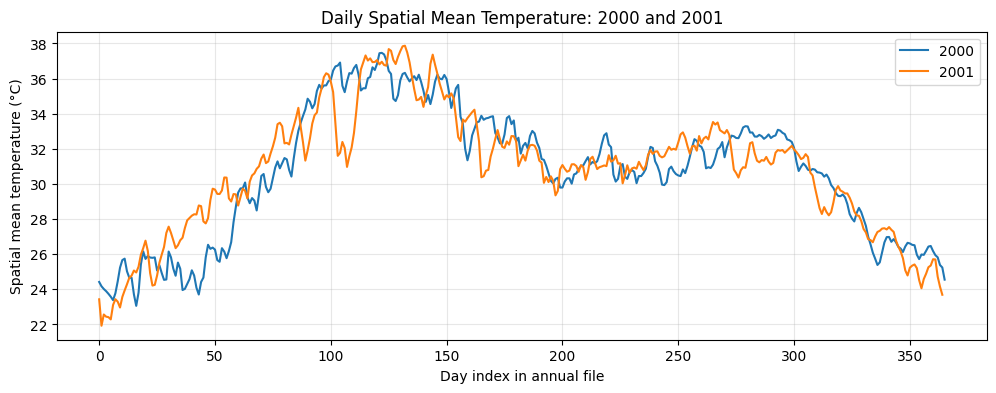

In [17]:
# Load 2000 and 2001 temperature datasets
ds_2000 = xr.open_dataset(temperature_files[0])
ds_2001 = xr.open_dataset(temperature_files[1])

# Calculate spatial mean for each daily observation
daily_mean_2000 = (
    ds_2000["temperature"]
    .mean(dim=["lat", "lon"], skipna=True)
    .values
)

daily_mean_2001 = (
    ds_2001["temperature"]
    .mean(dim=["lat", "lon"], skipna=True)
    .values
)

# Divide observations into months by their position in the annual array
def positional_monthly_mean(values, year):
    dates = pd.date_range(
        start=f"{year}-01-01",
        periods=len(values),
        freq="D"
    )

    df = pd.DataFrame({
        "date": dates,
        "daily_spatial_mean": values
    })

    return df.groupby(df["date"].dt.month)["daily_spatial_mean"].mean()

monthly_2000 = positional_monthly_mean(daily_mean_2000, 2000)
monthly_2001 = positional_monthly_mean(daily_mean_2001, 2001)

monthly_report = pd.DataFrame({
    "month": range(1, 13),
    "2000_mean_temp": monthly_2000.values,
    "2001_mean_temp": monthly_2001.values
})

display(monthly_report.round(2))

# Plot positional daily temperature sequence
plt.figure(figsize=(12, 4))
plt.plot(daily_mean_2000, label="2000")
plt.plot(daily_mean_2001, label="2001")
plt.xlabel("Day index in annual file")
plt.ylabel("Spatial mean temperature (°C)")
plt.title("Daily Spatial Mean Temperature: 2000 and 2001")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

ds_2000.close()
ds_2001.close()

In [18]:
# Inspect GRD file sizes and binary headers

for file in temperature_grd_files:
    print("\nFile:", file.name)
    print("Size (bytes):", file.stat().st_size)
    print("Size (MB):", round(file.stat().st_size / (1024**2), 3))

    with open(file, "rb") as f:
        header = f.read(64)

    print("First 64 bytes (hex):")
    print(header.hex(" "))


File: Maxtemp_MaxT_2024.GRD
Size (bytes): 1406904
Size (MB): 1.342
First 64 bytes (hex):
cd cc c7 42 cd cc c7 42 cd cc c7 42 cd cc c7 42 cd cc c7 42 cd cc c7 42 cd cc c7 42 cd cc c7 42 cd cc c7 42 cd cc c7 42 cd cc c7 42 cd cc c7 42 cd cc c7 42 cd cc c7 42 cd cc c7 42 cd cc c7 42

File: Maxtemp_MaxT_2025.GRD
Size (bytes): 1403060
Size (MB): 1.338
First 64 bytes (hex):
cd cc c7 42 cd cc c7 42 cd cc c7 42 cd cc c7 42 cd cc c7 42 cd cc c7 42 cd cc c7 42 cd cc c7 42 cd cc c7 42 cd cc c7 42 cd cc c7 42 cd cc c7 42 cd cc c7 42 cd cc c7 42 cd cc c7 42 cd cc c7 42


In [19]:
import numpy as np

for file in temperature_grd_files:

    raw = np.fromfile(file, dtype="<f4")

    print("\nFile:", file.name)
    print("Total float32 values:", len(raw))
    print("First 20 values:", raw[:20])
    print("Last 10 values:", raw[-10:])

    print("\nBasic statistics:")
    print("Minimum:", np.nanmin(raw))
    print("Maximum:", np.nanmax(raw))
    print("Mean:", np.nanmean(raw))
    print("Standard deviation:", np.nanstd(raw))

    print("\nSpecial values:")
    print("Count of 99.9:", np.sum(np.isclose(raw, 99.9)))
    print("Count of NaN:", np.isnan(raw).sum())

    print("\nExpected values for 31 x 31 grid:")
    print("365 days:", 365 * 31 * 31)
    print("366 days:", 366 * 31 * 31)


File: Maxtemp_MaxT_2024.GRD
Total float32 values: 351726
First 20 values: [99.9 99.9 99.9 99.9 99.9 99.9 99.9 99.9 99.9 99.9 99.9 99.9 99.9 99.9
 99.9 99.9 99.9 99.9 99.9 99.9]
Last 10 values: [99.9 99.9 99.9 99.9 99.9 99.9 99.9 99.9 99.9 99.9]

Basic statistics:
Minimum: 3.5872378
Maximum: 99.9
Mean: 74.44526
Standard deviation: 33.482914

Special values:
Count of 99.9: 221932
Count of NaN: 0

Expected values for 31 x 31 grid:
365 days: 350765
366 days: 351726

File: Maxtemp_MaxT_2025.GRD
Total float32 values: 350765
First 20 values: [99.9 99.9 99.9 99.9 99.9 99.9 99.9 99.9 99.9 99.9 99.9 99.9 99.9 99.9
 99.9 99.9 99.9 99.9 99.9 99.9]
Last 10 values: [99.9 99.9 99.9 99.9 99.9 99.9 99.9 99.9 99.9 99.9]

Basic statistics:
Minimum: 5.306739
Maximum: 99.9
Mean: 74.30617
Standard deviation: 33.598465

Special values:
Count of 99.9: 221213
Count of NaN: 0

Expected values for 31 x 31 grid:
365 days: 350765
366 days: 351726


In [20]:
temperature_grd_report = []

for file in temperature_grd_files:

    year = int(file.stem[-4:])

    # Read little-endian float32 data
    raw = np.fromfile(file, dtype="<f4")

    # Determine expected number of days
    expected_days = 366 if pd.Timestamp(
        f"{year}-12-31"
    ).dayofyear == 366 else 365

    # Reshape into daily 31 x 31 grids
    temp_array = raw.reshape(expected_days, 31, 31)

    # Convert IMD missing-value marker to NaN
    temp_array[temp_array == 99.9] = np.nan

    valid = temp_array[np.isfinite(temp_array)]

    temperature_grd_report.append({
        "year": year,
        "days": expected_days,
        "shape": temp_array.shape,
        "valid_values": len(valid),
        "missing_values": int(np.isnan(temp_array).sum()),
        "minimum_C": float(np.min(valid)),
        "maximum_C": float(np.max(valid)),
        "mean_C": float(np.mean(valid)),
        "std_C": float(np.std(valid))
    })

    print(f"\n{year}:")
    print("Array shape:", temp_array.shape)
    print("First-day valid cells:", np.isfinite(temp_array[0]).sum())
    print("Last-day valid cells:", np.isfinite(temp_array[-1]).sum())

display(pd.DataFrame(temperature_grd_report).round(3))


2024:
Array shape: (366, 31, 31)
First-day valid cells: 355
Last-day valid cells: 355

2025:
Array shape: (365, 31, 31)
First-day valid cells: 355
Last-day valid cells: 355


,year,days,shape,valid_values,missing_values,minimum_C,maximum_C,mean_C,std_C
0,2024,366,"(366, 31, 31)",129794,221932,3.587,48.095,30.921,5.981
1,2025,365,"(365, 31, 31)",129552,221213,5.307,46.153,30.604,5.295



Year: 2024
Completely missing cells: 606
Partially missing cells: 8
Cells with complete daily observations: 347
Minimum valid days: 0
Median valid days: 0.0
Maximum valid days: 366


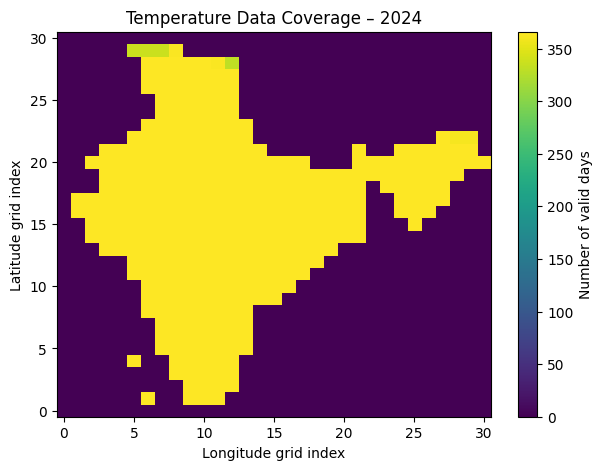


Year: 2025
Completely missing cells: 606
Partially missing cells: 6
Cells with complete daily observations: 349
Minimum valid days: 0
Median valid days: 0.0
Maximum valid days: 365


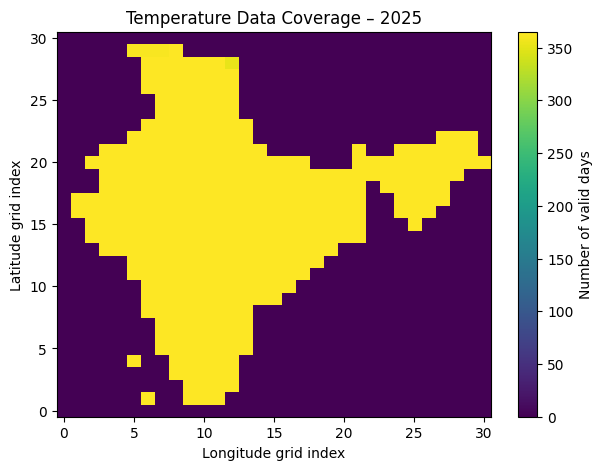

In [21]:
for file in temperature_grd_files:

    year = int(file.stem[-4:])
    raw = np.fromfile(file, dtype="<f4")

    days = 366 if year % 4 == 0 else 365

    temp_array = raw.reshape(days, 31, 31)
    temp_array[temp_array == 99.9] = np.nan

    # Number of valid days at each grid cell
    valid_days = np.isfinite(temp_array).sum(axis=0)

    # Classify grid cells
    completely_missing = np.sum(valid_days == 0)
    partially_missing = np.sum(
        (valid_days > 0) & (valid_days < days)
    )
    complete_coverage = np.sum(valid_days == days)

    print(f"\nYear: {year}")
    print("Completely missing cells:", completely_missing)
    print("Partially missing cells:", partially_missing)
    print("Cells with complete daily observations:", complete_coverage)
    print("Minimum valid days:", valid_days.min())
    print("Median valid days:", np.median(valid_days))
    print("Maximum valid days:", valid_days.max())

    plt.figure(figsize=(7, 5))
    plt.imshow(valid_days, origin="lower", aspect="auto")
    plt.colorbar(label="Number of valid days")
    plt.title(f"Temperature Data Coverage – {year}")
    plt.xlabel("Longitude grid index")
    plt.ylabel("Latitude grid index")
    plt.show()

In [22]:
grd_masks = {}

for file in temperature_grd_files:

    year = int(file.stem[-4:])
    raw = np.fromfile(file, dtype="<f4")

    days = 366 if year % 4 == 0 else 365

    temp_array = raw.reshape(days, 31, 31)

    # True means at least one valid observation during the year
    grd_masks[year] = np.isfinite(
        np.where(temp_array == 99.9, np.nan, temp_array)
    ).any(axis=0)

mask_2024 = grd_masks[2024]
mask_2025 = grd_masks[2025]

print("2024 valid spatial cells:", int(mask_2024.sum()))
print("2025 valid spatial cells:", int(mask_2025.sum()))

print("Cells valid in both years:",
      int((mask_2024 & mask_2025).sum()))

print("Cells valid only in 2024:",
      int((mask_2024 & ~mask_2025).sum()))

print("Cells valid only in 2025:",
      int((mask_2025 & ~mask_2024).sum()))

print("Identical spatial masks:",
      np.array_equal(mask_2024, mask_2025))

2024 valid spatial cells: 355
2025 valid spatial cells: 355
Cells valid in both years: 355
Cells valid only in 2024: 0
Cells valid only in 2025: 0
Identical spatial masks: True


In [23]:
temperature_netcdf_masks = {}
temperature_netcdf_coverage = []

for file in temperature_files:

    year = int(file.stem[-4:])

    ds = xr.open_dataset(file)
    temp = ds["temperature"]

    # Identify cells having at least one valid observation
    valid_mask = temp.notnull().any(dim="time").values

    temperature_netcdf_masks[year] = valid_mask

    temperature_netcdf_coverage.append({
        "year": year,
        "valid_spatial_cells": int(valid_mask.sum()),
        "completely_missing_cells": int(valid_mask.size - valid_mask.sum())
    })

    ds.close()

temperature_netcdf_coverage_df = pd.DataFrame(
    temperature_netcdf_coverage
)

display(temperature_netcdf_coverage_df)

# Compare every year with the 2000 spatial mask
reference_temp_mask = temperature_netcdf_masks[2000]

print("\n--- Spatial Mask Consistency ---")

for year, mask in temperature_netcdf_masks.items():

    different_cells = int(np.sum(mask != reference_temp_mask))

    print(
        year,
        "| Valid cells:", int(mask.sum()),
        "| Different cells from 2000:", different_cells
    )

,year,valid_spatial_cells,completely_missing_cells
0,2000,351,610
1,2001,353,608
2,2002,353,608
3,2003,358,603
4,2004,354,607
5,2005,354,607
6,2006,360,601
7,2007,356,605
8,2008,356,605
9,2009,353,608



--- Spatial Mask Consistency ---
2000 | Valid cells: 351 | Different cells from 2000: 0
2001 | Valid cells: 353 | Different cells from 2000: 4
2002 | Valid cells: 353 | Different cells from 2000: 4
2003 | Valid cells: 358 | Different cells from 2000: 7
2004 | Valid cells: 354 | Different cells from 2000: 3
2005 | Valid cells: 354 | Different cells from 2000: 3
2006 | Valid cells: 360 | Different cells from 2000: 9
2007 | Valid cells: 356 | Different cells from 2000: 5
2008 | Valid cells: 356 | Different cells from 2000: 5
2009 | Valid cells: 353 | Different cells from 2000: 4
2010 | Valid cells: 353 | Different cells from 2000: 4
2011 | Valid cells: 355 | Different cells from 2000: 6
2012 | Valid cells: 355 | Different cells from 2000: 6
2013 | Valid cells: 355 | Different cells from 2000: 6
2014 | Valid cells: 355 | Different cells from 2000: 6
2015 | Valid cells: 355 | Different cells from 2000: 6
2016 | Valid cells: 355 | Different cells from 2000: 6
2017 | Valid cells: 355 | Diffe

Total grid cells: 961
Valid in all 26 years: 349
Valid in at least 24 years: 350
Valid in at least 20 years: 353
Valid in at least 15 years: 355
Never valid: 601


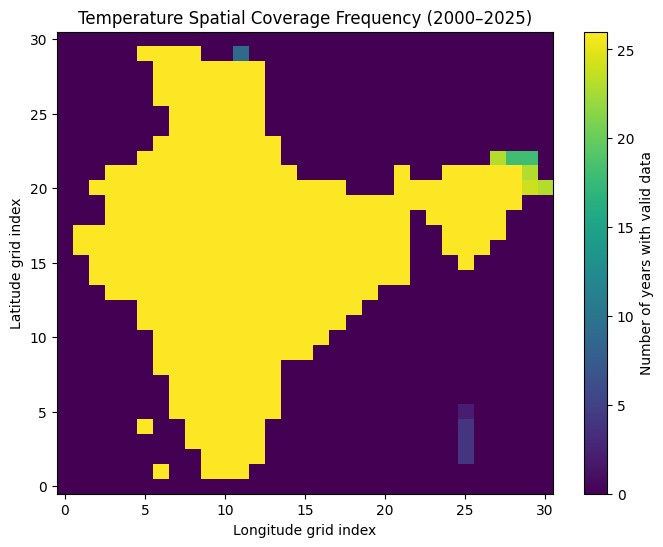

In [24]:
# Combine all annual temperature masks (2000–2025)
all_temperature_masks = {}

all_temperature_masks.update(temperature_netcdf_masks)
all_temperature_masks.update(grd_masks)

# Count how many years each grid cell has valid observations
mask_frequency = np.zeros((31, 31), dtype=int)

for year in range(2000, 2026):
    mask_frequency += all_temperature_masks[year].astype(int)

# Classify grid cells by coverage frequency
print("Total grid cells:", mask_frequency.size)
print("Valid in all 26 years:", int((mask_frequency == 26).sum()))
print("Valid in at least 24 years:", int((mask_frequency >= 24).sum()))
print("Valid in at least 20 years:", int((mask_frequency >= 20).sum()))
print("Valid in at least 15 years:", int((mask_frequency >= 15).sum()))
print("Never valid:", int((mask_frequency == 0).sum()))

# Plot temporal spatial coverage
plt.figure(figsize=(8, 6))
plt.imshow(mask_frequency, origin="lower", aspect="auto",
           vmin=0, vmax=26)
plt.colorbar(label="Number of years with valid data")
plt.title("Temperature Spatial Coverage Frequency (2000–2025)")
plt.xlabel("Longitude grid index")
plt.ylabel("Latitude grid index")
plt.show()

In [25]:
# Identify cells that are not valid in all 26 years
inconsistent_cells = np.argwhere(
    (mask_frequency > 0) & (mask_frequency < 26)
)

print("Cells with intermittent coverage:", len(inconsistent_cells))

inconsistent_report = []

for lat_idx, lon_idx in inconsistent_cells:

    missing_years = [
        year for year in range(2000, 2026)
        if not all_temperature_masks[year][lat_idx, lon_idx]
    ]

    inconsistent_report.append({
        "latitude_index": lat_idx,
        "longitude_index": lon_idx,
        "valid_years": int(mask_frequency[lat_idx, lon_idx]),
        "missing_years": missing_years
    })

inconsistent_df = pd.DataFrame(inconsistent_report)

display(inconsistent_df)

Cells with intermittent coverage: 11


,latitude_index,longitude_index,valid_years,missing_years
0,2,25,4,"[2000, 2004, 2005, 2007, 2008, 2009, 2010, 201..."
1,3,25,4,"[2000, 2004, 2005, 2007, 2008, 2009, 2010, 201..."
2,4,25,4,"[2000, 2004, 2005, 2007, 2008, 2009, 2010, 201..."
3,5,25,2,"[2000, 2001, 2002, 2004, 2005, 2007, 2008, 200..."
4,20,29,24,"[2001, 2002]"
5,20,30,23,"[2000, 2001, 2002]"
6,21,29,23,"[2000, 2001, 2002]"
7,22,27,23,"[2000, 2001, 2002]"
8,22,28,18,"[2000, 2001, 2002, 2003, 2004, 2005, 2009, 2010]"
9,22,29,18,"[2000, 2001, 2002, 2003, 2004, 2005, 2009, 2010]"


In [26]:
# Obtain latitude and longitude coordinates from a NetCDF file
ds = xr.open_dataset(temperature_files[0])

lat_values = ds["lat"].values
lon_values = ds["lon"].values

ds.close()

# Create a geographic report
inconsistent_df["latitude"] = inconsistent_df[
    "latitude_index"
].map(lambda i: lat_values[i])

inconsistent_df["longitude"] = inconsistent_df[
    "longitude_index"
].map(lambda i: lon_values[i])

print("--- Intermittent Temperature Grid Cells ---")

display(
    inconsistent_df[
        [
            "latitude_index",
            "longitude_index",
            "latitude",
            "longitude",
            "valid_years",
            "missing_years"
        ]
    ]
)

# Also report the geographic extent of the 349 common cells
common_mask = mask_frequency == 26

common_lat_indices, common_lon_indices = np.where(common_mask)

print("\n--- Common 349-Cell Spatial Extent ---")
print("Latitude:", lat_values[common_lat_indices].min(),
      "to", lat_values[common_lat_indices].max())

print("Longitude:", lon_values[common_lon_indices].min(),
      "to", lon_values[common_lon_indices].max())

--- Intermittent Temperature Grid Cells ---


,latitude_index,longitude_index,latitude,longitude,valid_years,missing_years
0,2,25,9.5,92.5,4,"[2000, 2004, 2005, 2007, 2008, 2009, 2010, 201..."
1,3,25,10.5,92.5,4,"[2000, 2004, 2005, 2007, 2008, 2009, 2010, 201..."
2,4,25,11.5,92.5,4,"[2000, 2004, 2005, 2007, 2008, 2009, 2010, 201..."
3,5,25,12.5,92.5,2,"[2000, 2001, 2002, 2004, 2005, 2007, 2008, 200..."
4,20,29,27.5,96.5,24,"[2001, 2002]"
5,20,30,27.5,97.5,23,"[2000, 2001, 2002]"
6,21,29,28.5,96.5,23,"[2000, 2001, 2002]"
7,22,27,29.5,94.5,23,"[2000, 2001, 2002]"
8,22,28,29.5,95.5,18,"[2000, 2001, 2002, 2003, 2004, 2005, 2009, 2010]"
9,22,29,29.5,96.5,18,"[2000, 2001, 2002, 2003, 2004, 2005, 2009, 2010]"



--- Common 349-Cell Spatial Extent ---
Latitude: 8.5 to 36.5
Longitude: 68.5 to 95.5


In [27]:
from sklearn.neighbors import BallTree

# Extract coordinates of the 349 common temperature cells
common_lat_idx, common_lon_idx = np.where(common_mask)

temperature_grid_coords = np.column_stack([
    lat_values[common_lat_idx],
    lon_values[common_lon_idx]
])

# Research node coordinates
node_coords = grid_nodes[["latitude", "longitude"]].values

# Convert coordinates to radians
temperature_rad = np.radians(temperature_grid_coords)
nodes_rad = np.radians(node_coords)

# Build Haversine BallTree
temp_tree = BallTree(temperature_rad, metric="haversine")

# Find nearest temperature grid cell
distances, indices = temp_tree.query(nodes_rad, k=1)

# Convert distances to kilometres
nearest_temp_dist_km = distances[:, 0] * 6371.0

# Summary
print("--- Temperature Grid Coverage of Research Nodes ---")
print("Research nodes:", len(node_coords))
print("Temperature grid cells:", len(temperature_grid_coords))

print("\nNearest distance statistics (km):")
print("Minimum:", round(nearest_temp_dist_km.min(), 2))
print("Mean:", round(nearest_temp_dist_km.mean(), 2))
print("Median:", round(np.median(nearest_temp_dist_km), 2))
print("95th percentile:", round(np.percentile(nearest_temp_dist_km, 95), 2))
print("Maximum:", round(nearest_temp_dist_km.max(), 2))

print("\nNodes within distance thresholds:")
for threshold in [25, 40, 50, 75, 100, 150]:
    count = int((nearest_temp_dist_km <= threshold).sum())
    print(f"Within {threshold} km: {count}")

--- Temperature Grid Coverage of Research Nodes ---
Research nodes: 5040
Temperature grid cells: 349

Nearest distance statistics (km):
Minimum: 5.28
Mean: 48.15
Median: 45.36
95th percentile: 65.82
Maximum: 1620.85

Nodes within distance thresholds:
Within 25 km: 643
Within 40 km: 2143
Within 50 km: 3507
Within 75 km: 4958
Within 100 km: 4980
Within 150 km: 5003


In [28]:
# Identify nodes with large nearest-temperature distances

temperature_node_coverage = grid_nodes.copy()

temperature_node_coverage["nearest_temp_distance_km"] = (
    nearest_temp_dist_km
)

temperature_node_coverage["nearest_temp_grid_lat"] = (
    temperature_grid_coords[indices[:, 0], 0]
)

temperature_node_coverage["nearest_temp_grid_lon"] = (
    temperature_grid_coords[indices[:, 0], 1]
)

distant_nodes = temperature_node_coverage[
    temperature_node_coverage["nearest_temp_distance_km"] > 100
].copy()

distant_nodes = distant_nodes.sort_values(
    "nearest_temp_distance_km",
    ascending=False
)

print("Nodes more than 100 km away:", len(distant_nodes))

display(distant_nodes)

Nodes more than 100 km away: 60


,latitude,longitude,nearest_temp_distance_km,nearest_temp_grid_lat,nearest_temp_grid_lon
3852,6.880740,94.151530,1620.845426,12.5,80.5
3855,7.057984,94.149049,1612.765631,12.5,80.5
3853,6.895961,94.050953,1610.001640,12.5,80.5
3854,7.066003,94.024939,1599.823327,12.5,80.5
3850,9.173042,92.951590,1378.696551,17.5,83.5
3851,9.240889,92.956195,1373.916521,17.5,83.5
3857,10.632691,92.670611,1239.740017,18.5,84.5
3856,10.629388,92.579049,1233.049736,18.5,84.5
3859,10.798196,92.666766,1226.314109,18.5,84.5
3858,10.775226,92.580181,1221.495356,18.5,84.5


In [29]:
# Classify nodes using their geographic coordinates

def classify_region(row):
    lat = row["latitude"]
    lon = row["longitude"]

    if lon > 90 and lat < 15:
        return "Andaman and Nicobar"

    elif lon < 73 and lat > 8:
        return "Lakshadweep"

    elif lon > 95 and lat > 26:
        return "Northeastern boundary"

    else:
        return "Other boundary"

temperature_node_coverage["region"] = (
    temperature_node_coverage.apply(classify_region, axis=1)
)

# Summarise nodes with nearest distance above 100 km
distant_summary = (
    temperature_node_coverage[
        temperature_node_coverage["nearest_temp_distance_km"] > 100
    ]
    .groupby("region")
    .agg(
        node_count=("latitude", "count"),
        minimum_distance_km=("nearest_temp_distance_km", "min"),
        maximum_distance_km=("nearest_temp_distance_km", "max"),
        mean_distance_km=("nearest_temp_distance_km", "mean")
    )
    .round(2)
    .reset_index()
)

display(distant_summary)

,region,node_count,minimum_distance_km,maximum_distance_km,mean_distance_km
0,Andaman and Nicobar,27,999.24,1620.85,1209.74
1,Lakshadweep,4,106.33,115.09,111.06
2,Northeastern boundary,29,103.51,190.17,137.29


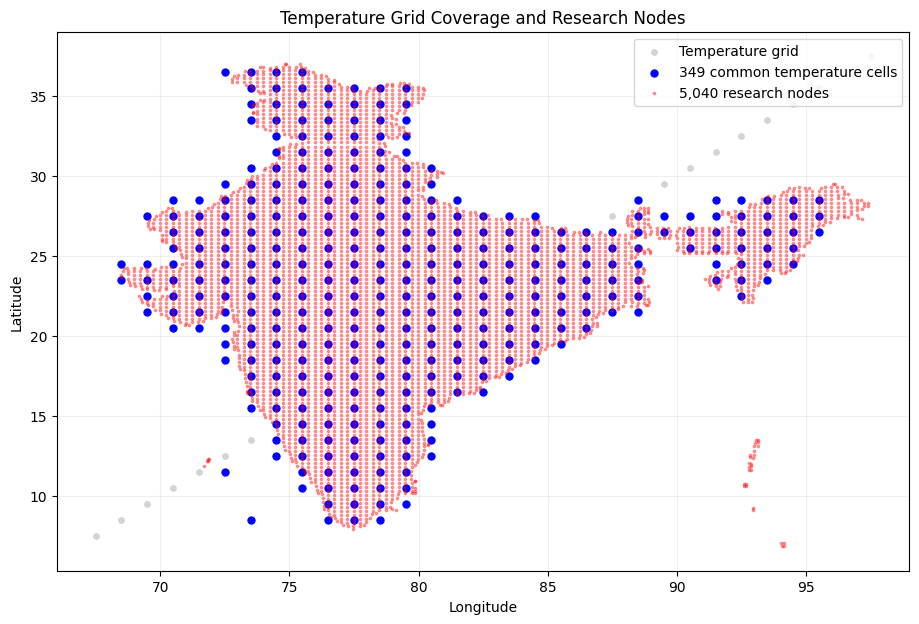

In [30]:
plt.figure(figsize=(11, 7))

# All temperature grid cells
plt.scatter(
    lon_values,
    lat_values,
    s=15,
    color="lightgrey",
    label="Temperature grid"
)

# Common valid temperature cells
plt.scatter(
    temperature_grid_coords[:, 1],
    temperature_grid_coords[:, 0],
    s=25,
    color="blue",
    label="349 common temperature cells"
)

# Research nodes
plt.scatter(
    grid_nodes["longitude"],
    grid_nodes["latitude"],
    s=3,
    color="red",
    alpha=0.35,
    label="5,040 research nodes"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Temperature Grid Coverage and Research Nodes")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [31]:
# Check four-corner bilinear interpolation support

supported_nodes = []

for _, node in grid_nodes.iterrows():

    lat = node["latitude"]
    lon = node["longitude"]

    # Find surrounding coordinate indices
    lat_lower = np.searchsorted(lat_values, lat) - 1
    lon_lower = np.searchsorted(lon_values, lon) - 1

    lat_upper = lat_lower + 1
    lon_upper = lon_lower + 1

    # Check whether node lies within grid boundaries
    if (lat_lower < 0 or lon_lower < 0 or
        lat_upper >= len(lat_values) or
        lon_upper >= len(lon_values)):

        supported_nodes.append(False)
        continue

    # Check all four surrounding cells
    corners = [
        (lat_lower, lon_lower),
        (lat_lower, lon_upper),
        (lat_upper, lon_lower),
        (lat_upper, lon_upper)
    ]

    all_valid = all(
        common_mask[i, j] for i, j in corners
    )

    supported_nodes.append(all_valid)

temperature_node_coverage["bilinear_supported"] = supported_nodes

print("--- Bilinear Interpolation Support ---")
print("Total research nodes:", len(supported_nodes))
print("Nodes with four valid surrounding cells:", sum(supported_nodes))
print("Nodes without complete support:", len(supported_nodes) - sum(supported_nodes))

print("\n--- Support by Geographic Region ---")

display(
    temperature_node_coverage.groupby("region")[
        "bilinear_supported"
    ].agg(["count", "sum"])
)

--- Bilinear Interpolation Support ---
Total research nodes: 5040
Nodes with four valid surrounding cells: 4427
Nodes without complete support: 613

--- Support by Geographic Region ---


,count,sum
region,,
Andaman and Nicobar,27,0
Lakshadweep,458,385
Northeastern boundary,86,15
Other boundary,4469,4027


In [32]:
# Inspect nodes without complete bilinear support

unsupported_nodes = temperature_node_coverage[
    ~temperature_node_coverage["bilinear_supported"]
].copy()

print("Unsupported nodes:", len(unsupported_nodes))

print("\nAvailable columns:")
print(unsupported_nodes.columns.tolist())

display(
    unsupported_nodes[
        ["latitude", "longitude", "region"]
    ].sort_values(["latitude", "longitude"]).head(30)
)

Unsupported nodes: 613

Available columns:
['latitude', 'longitude', 'nearest_temp_distance_km', 'nearest_temp_grid_lat', 'nearest_temp_grid_lon', 'region', 'bilinear_supported']


,latitude,longitude,region
3852,6.880740,94.151530,Andaman and Nicobar
3853,6.895961,94.050953,Andaman and Nicobar
3855,7.057984,94.149049,Andaman and Nicobar
3854,7.066003,94.024939,Andaman and Nicobar
121,7.976934,77.477200,Other boundary
123,8.118645,77.476292,Other boundary
122,8.147642,77.256371,Other boundary
127,8.161663,77.718478,Other boundary
124,8.209111,77.080193,Other boundary
128,8.209681,77.893980,Other boundary


In [33]:
# Classify why bilinear interpolation is unsupported

support_status = []

for _, node in grid_nodes.iterrows():

    lat = node["latitude"]
    lon = node["longitude"]

    lat_lower = np.searchsorted(lat_values, lat) - 1
    lon_lower = np.searchsorted(lon_values, lon) - 1

    lat_upper = lat_lower + 1
    lon_upper = lon_lower + 1

    if (lat_lower < 0 or lon_lower < 0 or
        lat_upper >= len(lat_values) or
        lon_upper >= len(lon_values)):

        support_status.append("Outside grid boundaries")
        continue

    corners = [
        (lat_lower, lon_lower),
        (lat_lower, lon_upper),
        (lat_upper, lon_lower),
        (lat_upper, lon_upper)
    ]

    valid_count = sum(
        common_mask[i, j] for i, j in corners
    )

    if valid_count == 4:
        support_status.append("Supported")
    else:
        support_status.append(
            f"Missing surrounding cells ({valid_count}/4 valid)"
        )

temperature_node_coverage["support_status"] = support_status

print("--- Interpolation Support Classification ---")

display(
    temperature_node_coverage["support_status"]
    .value_counts()
    .to_frame("Number of nodes")
)

print("\n--- Unsupported Nodes by Latitude Range ---")

unsupported_nodes = temperature_node_coverage[
    temperature_node_coverage["support_status"] != "Supported"
].copy()

unsupported_nodes["latitude_band"] = pd.cut(
    unsupported_nodes["latitude"],
    bins=[0, 10, 15, 20, 25, 30, 35, 40],
    include_lowest=True
)

display(
    unsupported_nodes.groupby(
        "latitude_band", observed=False
    ).size().to_frame("Unsupported nodes")
)

--- Interpolation Support Classification ---


,Number of nodes
support_status,
Supported,4427
Missing surrounding cells (3/4 valid),312
Missing surrounding cells (2/4 valid),207
Missing surrounding cells (1/4 valid),45
Missing surrounding cells (0/4 valid),45
Outside grid boundaries,4



--- Unsupported Nodes by Latitude Range ---


,Unsupported nodes
latitude_band,
"(-0.001, 10.0]",30
"(10.0, 15.0]",64
"(15.0, 20.0]",63
"(20.0, 25.0]",103
"(25.0, 30.0]",240
"(30.0, 35.0]",33
"(35.0, 40.0]",80


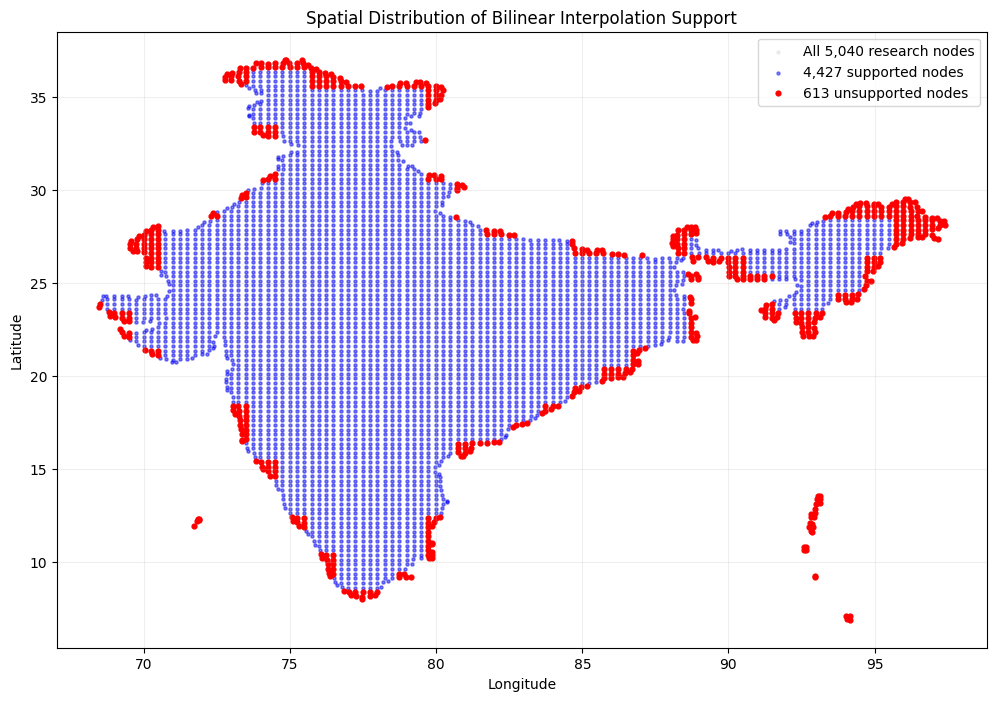

In [34]:
plt.figure(figsize=(12, 8))

# All research nodes
plt.scatter(
    grid_nodes["longitude"],
    grid_nodes["latitude"],
    s=5, color="lightgrey", alpha=0.35,
    label="All 5,040 research nodes"
)

# Supported nodes
supported = temperature_node_coverage[
    temperature_node_coverage["bilinear_supported"]
]

plt.scatter(
    supported["longitude"],
    supported["latitude"],
    s=5, color="blue", alpha=0.45,
    label="4,427 supported nodes"
)

# Unsupported nodes
unsupported = temperature_node_coverage[
    ~temperature_node_coverage["bilinear_supported"]
]

plt.scatter(
    unsupported["longitude"],
    unsupported["latitude"],
    s=12, color="red",
    label="613 unsupported nodes"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Spatial Distribution of Bilinear Interpolation Support")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [35]:
print("Temperature grid coordinate verification")

print("\nLatitude:")
print("Number of values:", len(lat_values))
print("First 10:", lat_values[:10])
print("Last 10:", lat_values[-10:])
print("Ascending:", np.all(np.diff(lat_values) > 0))
print("Descending:", np.all(np.diff(lat_values) < 0))

print("\nLongitude:")
print("Number of values:", len(lon_values))
print("First 10:", lon_values[:10])
print("Last 10:", lon_values[-10:])
print("Ascending:", np.all(np.diff(lon_values) > 0))
print("Descending:", np.all(np.diff(lon_values) < 0))

print("\nCommon mask:")
print("Shape:", common_mask.shape)
print("Valid cells:", np.sum(common_mask))
print("Missing cells:", np.sum(~common_mask))

Temperature grid coordinate verification

Latitude:
Number of values: 31
First 10: [ 7.5  8.5  9.5 10.5 11.5 12.5 13.5 14.5 15.5 16.5]
Last 10: [28.5 29.5 30.5 31.5 32.5 33.5 34.5 35.5 36.5 37.5]
Ascending: True
Descending: False

Longitude:
Number of values: 31
First 10: [67.5 68.5 69.5 70.5 71.5 72.5 73.5 74.5 75.5 76.5]
Last 10: [88.5 89.5 90.5 91.5 92.5 93.5 94.5 95.5 96.5 97.5]
Ascending: True
Descending: False

Common mask:
Shape: (31, 31)
Valid cells: 349
Missing cells: 612


In [36]:
# Inspect spatial coordinates and array orientation
sample_temp_file = temperature_files[0]

with xr.open_dataset(sample_temp_file) as ds:

    print("File:", sample_temp_file.name)

    print("\nDataset coordinates:")
    print("Latitude:", ds["lat"].values[:10])
    print("Longitude:", ds["lon"].values[:10])

    print("\nCoordinate ordering:")
    print("Latitude ascending:",
          np.all(np.diff(ds["lat"].values) > 0))
    print("Latitude descending:",
          np.all(np.diff(ds["lat"].values) < 0))

    print("Longitude ascending:",
          np.all(np.diff(ds["lon"].values) > 0))
    print("Longitude descending:",
          np.all(np.diff(ds["lon"].values) < 0))

    print("\nCoordinate match:")
    print("Latitude matches:",
          np.array_equal(ds["lat"].values, lat_values))
    print("Longitude matches:",
          np.array_equal(ds["lon"].values, lon_values))

    print("\nTemperature array shape:", ds["temperature"].shape)

File: Maxtemp_MaxT_2000.nc

Dataset coordinates:
Latitude: [ 7.5  8.5  9.5 10.5 11.5 12.5 13.5 14.5 15.5 16.5]
Longitude: [67.5 68.5 69.5 70.5 71.5 72.5 73.5 74.5 75.5 76.5]

Coordinate ordering:
Latitude ascending: True
Latitude descending: False
Longitude ascending: True
Longitude descending: False

Coordinate match:
Latitude matches: True
Longitude matches: True

Temperature array shape: (366, 31, 31)


In [37]:
# Verify spatial coordinates across all 24 NetCDF files

coordinate_checks = []

for file in temperature_files:

    with xr.open_dataset(file) as ds:

        coordinate_checks.append({
            "file": file.name,
            "latitude_match": np.array_equal(
                ds["lat"].values, lat_values
            ),
            "longitude_match": np.array_equal(
                ds["lon"].values, lon_values
            ),
            "shape": ds["temperature"].shape
        })

coordinate_check_df = pd.DataFrame(coordinate_checks)

display(coordinate_check_df)

print("\nAll latitude coordinates match:",
      coordinate_check_df["latitude_match"].all())

print("All longitude coordinates match:",
      coordinate_check_df["longitude_match"].all())

,file,latitude_match,longitude_match,shape
0,Maxtemp_MaxT_2000.nc,True,True,"(366, 31, 31)"
1,Maxtemp_MaxT_2001.nc,True,True,"(365, 31, 31)"
2,Maxtemp_MaxT_2002.nc,True,True,"(365, 31, 31)"
3,Maxtemp_MaxT_2003.nc,True,True,"(365, 31, 31)"
4,Maxtemp_MaxT_2004.nc,True,True,"(366, 31, 31)"
5,Maxtemp_MaxT_2005.nc,True,True,"(365, 31, 31)"
6,Maxtemp_MaxT_2006.nc,True,True,"(365, 31, 31)"
7,Maxtemp_MaxT_2007.nc,True,True,"(365, 31, 31)"
8,Maxtemp_MaxT_2008.nc,True,True,"(366, 31, 31)"
9,Maxtemp_MaxT_2009.nc,True,True,"(365, 31, 31)"



All latitude coordinates match: True
All longitude coordinates match: True


In [45]:
# Audit time coordinates across all NetCDF temperature files

time_audit = []

for file in temperature_files:

    with xr.open_dataset(file) as ds:

        time_values = ds["time"].values
        time_encoding = ds["time"].encoding
        time_attrs = ds["time"].attrs

        time_audit.append({
            "file": file.name,
            "observations": len(time_values),
            "first_date": str(time_values[0]),
            "last_date": str(time_values[-1]),
            "time_units": time_encoding.get("units"),
            "calendar": time_encoding.get("calendar"),
            "time_attributes": str(time_attrs)
        })

time_audit_df = pd.DataFrame(time_audit)

display(time_audit_df)

print("\nUnique time units:")
print(time_audit_df["time_units"].unique())

print("\nUnique calendars:")
print(time_audit_df["calendar"].unique())

,file,observations,first_date,last_date,time_units,calendar,time_attributes
0,Maxtemp_MaxT_2000.nc,366,2023-01-01T00:00:00.000000000,2024-01-01T00:00:00.000000000,days since 2023-01-01 00:00:00,proleptic_gregorian,{}
1,Maxtemp_MaxT_2001.nc,365,2023-01-01T00:00:00.000000000,2023-12-31T00:00:00.000000000,days since 2023-01-01 00:00:00,proleptic_gregorian,{}
2,Maxtemp_MaxT_2002.nc,365,2023-01-01T00:00:00.000000000,2023-12-31T00:00:00.000000000,days since 2023-01-01 00:00:00,proleptic_gregorian,{}
3,Maxtemp_MaxT_2003.nc,365,2023-01-01T00:00:00.000000000,2023-12-31T00:00:00.000000000,days since 2023-01-01 00:00:00,proleptic_gregorian,{}
4,Maxtemp_MaxT_2004.nc,366,2023-01-01T00:00:00.000000000,2024-01-01T00:00:00.000000000,days since 2023-01-01 00:00:00,proleptic_gregorian,{}
5,Maxtemp_MaxT_2005.nc,365,2023-01-01T00:00:00.000000000,2023-12-31T00:00:00.000000000,days since 2023-01-01 00:00:00,proleptic_gregorian,{}
6,Maxtemp_MaxT_2006.nc,365,2023-01-01T00:00:00.000000000,2023-12-31T00:00:00.000000000,days since 2023-01-01 00:00:00,proleptic_gregorian,{}
7,Maxtemp_MaxT_2007.nc,365,2023-01-01T00:00:00.000000000,2023-12-31T00:00:00.000000000,days since 2023-01-01 00:00:00,proleptic_gregorian,{}
8,Maxtemp_MaxT_2008.nc,366,2023-01-01T00:00:00.000000000,2024-01-01T00:00:00.000000000,days since 2023-01-01 00:00:00,proleptic_gregorian,{}
9,Maxtemp_MaxT_2009.nc,365,2023-01-01T00:00:00.000000000,2023-12-31T00:00:00.000000000,days since 2023-01-01 00:00:00,proleptic_gregorian,{}



Unique time units:
['days since 2023-01-01 00:00:00']

Unique calendars:
['proleptic_gregorian']


In [39]:
# Audit 2024–2025 temperature GRD files

grd_audit = []

for file in temperature_grd_files:

    raw = np.fromfile(file, dtype="<f4")

    year = int(file.stem[-4:])
    expected_days = 366 if pd.Timestamp(
        f"{year}-12-31"
    ).is_leap_year else 365

    grd_audit.append({
        "file": file.name,
        "file_size_bytes": file.stat().st_size,
        "total_values": len(raw),
        "expected_values": expected_days * 31 * 31,
        "expected_days": expected_days,
        "dimension_match": len(raw) == expected_days * 31 * 31,
        "undefined_99_9_count": int(np.sum(raw == 99.9)),
        "minimum_raw": float(np.nanmin(raw)),
        "maximum_raw": float(np.nanmax(raw))
    })

grd_audit_df = pd.DataFrame(grd_audit)

display(grd_audit_df)

,file,file_size_bytes,total_values,expected_values,expected_days,dimension_match,undefined_99_9_count,minimum_raw,maximum_raw
0,Maxtemp_MaxT_2024.GRD,1406904,351726,351726,366,True,221932,3.587238,99.900002
1,Maxtemp_MaxT_2025.GRD,1403060,350765,350765,365,True,221213,5.306739,99.900002



2024 - First day
Shape: (31, 31)
Valid cells: 355
Minimum: 10.948511
Maximum: 32.793915
Mean: 23.38598


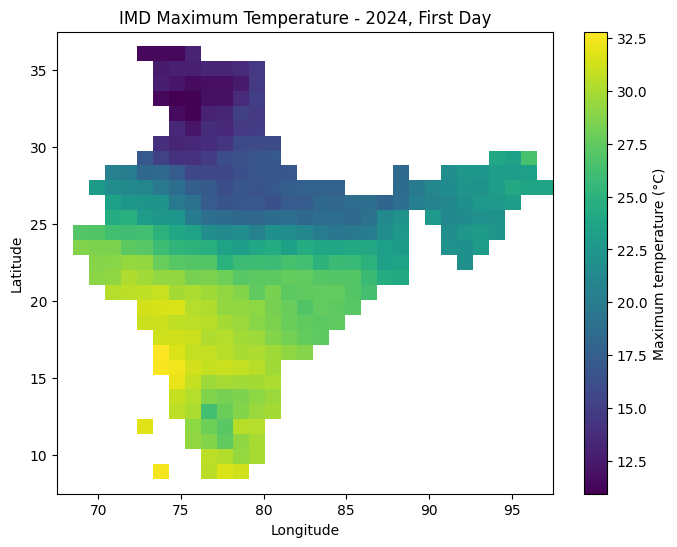


2025 - First day
Shape: (31, 31)
Valid cells: 355
Minimum: 7.5947313
Maximum: 33.244034
Mean: 22.995737


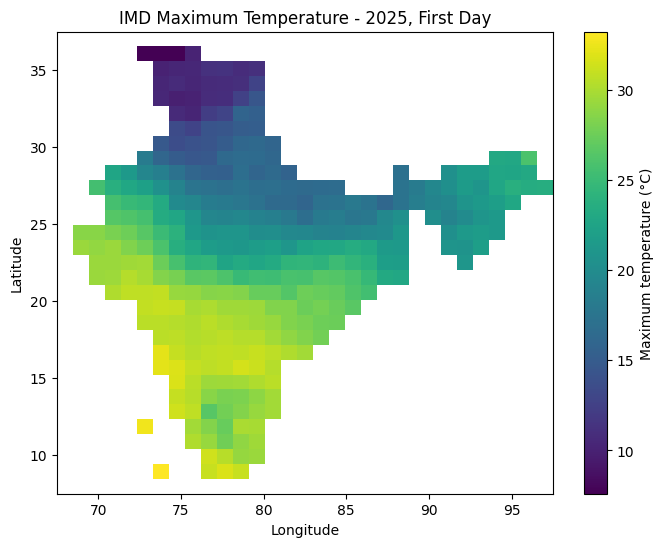

In [40]:
# Inspect first-day spatial patterns of 2024 and 2025 GRD files

for file in temperature_grd_files:

    year = int(file.stem[-4:])
    days = 366 if pd.Timestamp(f"{year}-12-31").is_leap_year else 365

    raw = np.fromfile(file, dtype="<f4")
    temp_array = raw.reshape(days, 31, 31)

    first_day = temp_array[0].copy()
    first_day[first_day == 99.9] = np.nan

    print(f"\n{year} - First day")
    print("Shape:", first_day.shape)
    print("Valid cells:", np.isfinite(first_day).sum())
    print("Minimum:", np.nanmin(first_day))
    print("Maximum:", np.nanmax(first_day))
    print("Mean:", np.nanmean(first_day))

    plt.figure(figsize=(8, 6))
    plt.imshow(
        first_day,
        origin="lower",
        aspect="auto",
        extent=[
            lon_values.min(), lon_values.max(),
            lat_values.min(), lat_values.max()
        ]
    )
    plt.colorbar(label="Maximum temperature (°C)")
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    plt.title(f"IMD Maximum Temperature - {year}, First Day")
    plt.show()

In [41]:
# Read and label the 2024 GRD temperature data

file_2024 = next(
    f for f in temperature_grd_files
    if "2024" in f.name
)

raw_2024 = np.fromfile(file_2024, dtype="<f4")

temperature_2024 = raw_2024.reshape(366, 31, 31).copy()

# Convert undefined values to NaN
temperature_2024[temperature_2024 == 99.9] = np.nan

# Create an xarray DataArray
temperature_2024_da = xr.DataArray(
    temperature_2024,
    dims=("time", "lat", "lon"),
    coords={
        "time": pd.date_range(
            "2024-01-01", periods=366, freq="D"
        ),
        "lat": lat_values,
        "lon": lon_values
    },
    name="maximum_temperature",
    attrs={"units": "degrees Celsius"}
)

print(temperature_2024_da)

print("\nSpatial coordinate verification:")
print("Latitude:", temperature_2024_da.lat.values[[0, -1]])
print("Longitude:", temperature_2024_da.lon.values[[0, -1]])
print("Valid cells on first day:",
      int(np.isfinite(temperature_2024_da.isel(time=0)).sum()))

<xarray.DataArray 'maximum_temperature' (time: 366, lat: 31, lon: 31)> Size: 1MB
array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
...
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
  

In [42]:
# Check 2024 temperature coverage against the 349-cell common mask

valid_2024 = np.isfinite(temperature_2024_da.values)

# Valid observations across all 366 days
valid_all_days = valid_2024.all(axis=0)

print("Common-mask cells:", int(common_mask.sum()))

print("\n2024 coverage:")
print("Cells valid throughout the year:",
      int(valid_all_days.sum()))

print("Common-mask cells valid throughout 2024:",
      int(np.sum(valid_all_days & common_mask)))

print("Common-mask cells with missing observations:",
      int(np.sum(common_mask & ~valid_all_days)))

print("\nDaily valid-cell statistics:")
daily_valid_counts = valid_2024.sum(axis=(1, 2))

print("Minimum:", daily_valid_counts.min())
print("Maximum:", daily_valid_counts.max())
print("Mean:", daily_valid_counts.mean())

Common-mask cells: 349

2024 coverage:
Cells valid throughout the year: 347
Common-mask cells valid throughout 2024: 343
Common-mask cells with missing observations: 6

Daily valid-cell statistics:
Minimum: 347
Maximum: 355
Mean: 354.62841530054646


In [43]:
# Read and label the 2025 GRD temperature data

file_2025 = next(
    f for f in temperature_grd_files
    if "2025" in f.name
)

raw_2025 = np.fromfile(file_2025, dtype="<f4")

temperature_2025 = raw_2025.reshape(365, 31, 31).copy()
temperature_2025[temperature_2025 == 99.9] = np.nan

temperature_2025_da = xr.DataArray(
    temperature_2025,
    dims=("time", "lat", "lon"),
    coords={
        "time": pd.date_range(
            "2025-01-01", periods=365, freq="D"
        ),
        "lat": lat_values,
        "lon": lon_values
    },
    name="maximum_temperature",
    attrs={"units": "degrees Celsius"}
)

# Check coverage
valid_2025 = np.isfinite(temperature_2025_da.values)

valid_all_days_2025 = valid_2025.all(axis=0)

daily_valid_counts_2025 = valid_2025.sum(axis=(1, 2))

print("Common-mask cells:", int(common_mask.sum()))

print("\n2025 coverage:")
print("Cells valid throughout the year:",
      int(valid_all_days_2025.sum()))

print("Common-mask cells valid throughout 2025:",
      int(np.sum(valid_all_days_2025 & common_mask)))

print("Common-mask cells with missing observations:",
      int(np.sum(common_mask & ~valid_all_days_2025)))

print("\nDaily valid-cell statistics:")
print("Minimum:", daily_valid_counts_2025.min())
print("Maximum:", daily_valid_counts_2025.max())
print("Mean:", daily_valid_counts_2025.mean())

Common-mask cells: 349

2025 coverage:
Cells valid throughout the year: 349
Common-mask cells valid throughout 2025: 345
Common-mask cells with missing observations: 4

Daily valid-cell statistics:
Minimum: 351
Maximum: 355
Mean: 354.93698630136987


In [44]:
# Compare annual spatial masks for 2024 and 2025

mask_2024 = np.isfinite(temperature_2024_da.values).any(axis=0)
mask_2025 = np.isfinite(temperature_2025_da.values).any(axis=0)

print("2024 valid spatial cells:", int(mask_2024.sum()))
print("2025 valid spatial cells:", int(mask_2025.sum()))

print("\nMask comparison:")
print("Common valid cells:", int((mask_2024 & mask_2025).sum()))
print("Valid only in 2024:", int((mask_2024 & ~mask_2025).sum()))
print("Valid only in 2025:", int((~mask_2024 & mask_2025).sum()))

print("\nMasks identical:", np.array_equal(mask_2024, mask_2025))

2024 valid spatial cells: 355
2025 valid spatial cells: 355

Mask comparison:
Common valid cells: 355
Valid only in 2024: 0
Valid only in 2025: 0

Masks identical: True


In [47]:
# Verify time coordinates across all rainfall NetCDF files

rainfall_time_audit = []

for file in rainfall_files:

    with xr.open_dataset(file) as ds:

        rainfall_time_audit.append({
            "file": file.name,
            "observations": len(ds["TIME"]),
            "start_date": str(ds["TIME"].values[0]),
            "end_date": str(ds["TIME"].values[-1]),
            "time_units": ds["TIME"].encoding.get("units")
        })

rainfall_time_audit_df = pd.DataFrame(rainfall_time_audit)

display(rainfall_time_audit_df)

,file,observations,start_date,end_date,time_units
0,RF25_ind2000_rfp25.nc,366,2000-01-01T00:00:00.000000000,2000-12-31T00:00:00.000000000,days since 1900-12-31 00:00:00
1,RF25_ind2001_rfp25.nc,365,2001-01-01T00:00:00.000000000,2001-12-31T00:00:00.000000000,days since 1900-12-31
2,RF25_ind2002_rfp25.nc,365,2002-01-01T00:00:00.000000000,2002-12-31T00:00:00.000000000,days since 1900-12-31
3,RF25_ind2003_rfp25.nc,365,2003-01-01T00:00:00.000000000,2003-12-31T00:00:00.000000000,days since 1900-12-31
4,RF25_ind2004_rfp25.nc,366,2004-01-01T00:00:00.000000000,2004-12-31T00:00:00.000000000,days since 1900-12-31
5,RF25_ind2005_rfp25.nc,365,2005-01-01T00:00:00.000000000,2005-12-31T00:00:00.000000000,days since 1900-12-31
6,RF25_ind2006_rfp25.nc,365,2006-01-01T00:00:00.000000000,2006-12-31T00:00:00.000000000,days since 1900-12-31
7,RF25_ind2007_rfp25.nc,365,2007-01-01T00:00:00.000000000,2007-12-31T00:00:00.000000000,days since 1900-12-31
8,RF25_ind2008_rfp25.nc,366,2008-01-01T00:00:00.000000000,2008-12-31T00:00:00.000000000,days since 1900-12-31
9,RF25_ind2009_rfp25.nc,365,2009-01-01T00:00:00.000000000,2009-12-31T00:00:00.000000000,days since 1900-12-31


In [48]:
all_dates = []

for file in rainfall_files:
    with xr.open_dataset(file) as ds:
        all_dates.extend(pd.to_datetime(ds["TIME"].values))

all_dates = pd.DatetimeIndex(all_dates)

print("Total observations:", len(all_dates))
print("First date:", all_dates.min())
print("Last date:", all_dates.max())
print("Unique dates:", all_dates.nunique())
print("Duplicate dates:", all_dates.duplicated().sum())

expected_dates = pd.date_range(
    start="2000-01-01",
    end="2025-12-31",
    freq="D"
)

print("Expected observations:", len(expected_dates))
print("Missing dates:", len(expected_dates.difference(all_dates)))

Total observations: 9497
First date: 2000-01-01 00:00:00
Last date: 2025-12-31 00:00:00
Unique dates: 9497
Duplicate dates: 0
Expected observations: 9497
Missing dates: 0


In [49]:
spatial_audit = []

for file in rainfall_files:
    with xr.open_dataset(file) as ds:
        spatial_audit.append({
            "file": file.name,
            "latitude_count": len(ds["LATITUDE"]),
            "longitude_count": len(ds["LONGITUDE"]),
            "latitude_min": float(ds["LATITUDE"].min()),
            "latitude_max": float(ds["LATITUDE"].max()),
            "longitude_min": float(ds["LONGITUDE"].min()),
            "longitude_max": float(ds["LONGITUDE"].max()),
        })

spatial_audit_df = pd.DataFrame(spatial_audit)
display(spatial_audit_df)

,file,latitude_count,longitude_count,latitude_min,latitude_max,longitude_min,longitude_max
0,RF25_ind2000_rfp25.nc,129,135,6.5,38.5,66.5,100.0
1,RF25_ind2001_rfp25.nc,129,135,6.5,38.5,66.5,100.0
2,RF25_ind2002_rfp25.nc,129,135,6.5,38.5,66.5,100.0
3,RF25_ind2003_rfp25.nc,129,135,6.5,38.5,66.5,100.0
4,RF25_ind2004_rfp25.nc,129,135,6.5,38.5,66.5,100.0
5,RF25_ind2005_rfp25.nc,129,135,6.5,38.5,66.5,100.0
6,RF25_ind2006_rfp25.nc,129,135,6.5,38.5,66.5,100.0
7,RF25_ind2007_rfp25.nc,129,135,6.5,38.5,66.5,100.0
8,RF25_ind2008_rfp25.nc,129,135,6.5,38.5,66.5,100.0
9,RF25_ind2009_rfp25.nc,129,135,6.5,38.5,66.5,100.0


In [50]:
reference_file = rainfall_files[0]

with xr.open_dataset(reference_file) as ds:
    reference_lat = ds["LATITUDE"].values.copy()
    reference_lon = ds["LONGITUDE"].values.copy()

coordinate_check = []

for file in rainfall_files:
    with xr.open_dataset(file) as ds:
        lat_match = np.array_equal(reference_lat, ds["LATITUDE"].values)
        lon_match = np.array_equal(reference_lon, ds["LONGITUDE"].values)

        coordinate_check.append({
            "file": file.name,
            "latitude_identical": lat_match,
            "longitude_identical": lon_match
        })

coordinate_check_df = pd.DataFrame(coordinate_check)
display(coordinate_check_df)

print("All latitude coordinates identical:",
      coordinate_check_df["latitude_identical"].all())

print("All longitude coordinates identical:",
      coordinate_check_df["longitude_identical"].all())

,file,latitude_identical,longitude_identical
0,RF25_ind2000_rfp25.nc,True,True
1,RF25_ind2001_rfp25.nc,True,True
2,RF25_ind2002_rfp25.nc,True,True
3,RF25_ind2003_rfp25.nc,True,True
4,RF25_ind2004_rfp25.nc,True,True
5,RF25_ind2005_rfp25.nc,True,True
6,RF25_ind2006_rfp25.nc,True,True
7,RF25_ind2007_rfp25.nc,True,True
8,RF25_ind2008_rfp25.nc,True,True
9,RF25_ind2009_rfp25.nc,True,True


All latitude coordinates identical: True
All longitude coordinates identical: True


In [51]:
missing_value_audit = []

for file in rainfall_files:
    with xr.open_dataset(file) as ds:
        rainfall = ds["RAINFALL"]

        total = rainfall.size
        missing = int(rainfall.isnull().sum().compute().item())
        valid = total - missing

        missing_value_audit.append({
            "year": file.stem.split("_")[1].replace("ind", ""),
            "total_values": total,
            "valid_values": valid,
            "missing_values": missing,
            "missing_percentage": round(missing / total * 100, 3)
        })

missing_audit_df = pd.DataFrame(missing_value_audit)
display(missing_audit_df)

,year,total_values,valid_values,missing_values,missing_percentage
0,2000,6373890,1816824,4557066,71.496
1,2001,6356475,1811860,4544615,71.496
2,2002,6356475,1811860,4544615,71.496
3,2003,6356475,1811860,4544615,71.496
4,2004,6373890,1816824,4557066,71.496
5,2005,6356475,1811860,4544615,71.496
6,2006,6356475,1811860,4544615,71.496
7,2007,6356475,1811860,4544615,71.496
8,2008,6373890,1816824,4557066,71.496
9,2009,6356475,1811860,4544615,71.496


In [52]:
annual_masks = []

for file in rainfall_files:
    with xr.open_dataset(file) as ds:
        mask = ds["RAINFALL"].notnull().any(dim="TIME").values
        annual_masks.append(mask)

reference_mask = annual_masks[0]

for i, mask in enumerate(annual_masks):
    print(
        rainfall_files[i].name,
        "Identical to 2000:",
        np.array_equal(reference_mask, mask),
        "Valid grid cells:",
        int(mask.sum()),
        "Different cells:",
        int(np.sum(reference_mask != mask))
    )

RF25_ind2000_rfp25.nc Identical to 2000: True Valid grid cells: 4964 Different cells: 0
RF25_ind2001_rfp25.nc Identical to 2000: True Valid grid cells: 4964 Different cells: 0
RF25_ind2002_rfp25.nc Identical to 2000: True Valid grid cells: 4964 Different cells: 0
RF25_ind2003_rfp25.nc Identical to 2000: True Valid grid cells: 4964 Different cells: 0
RF25_ind2004_rfp25.nc Identical to 2000: True Valid grid cells: 4964 Different cells: 0
RF25_ind2005_rfp25.nc Identical to 2000: True Valid grid cells: 4964 Different cells: 0
RF25_ind2006_rfp25.nc Identical to 2000: True Valid grid cells: 4964 Different cells: 0
RF25_ind2007_rfp25.nc Identical to 2000: True Valid grid cells: 4964 Different cells: 0
RF25_ind2008_rfp25.nc Identical to 2000: True Valid grid cells: 4964 Different cells: 0
RF25_ind2009_rfp25.nc Identical to 2000: True Valid grid cells: 4964 Different cells: 0
RF25_ind2010_rfp25.nc Identical to 2000: True Valid grid cells: 4964 Different cells: 0
RF25_ind2011_rfp25.nc Identical 

In [53]:
file_2023 = RAINFALL_DIR / "RF25_ind2023_rfp25.nc"

with xr.open_dataset(file_2023) as ds:
    rainfall_2023 = ds["RAINFALL"]

    missing_per_day = rainfall_2023.isnull().sum(
        dim=("LATITUDE", "LONGITUDE")
    )

    affected_days = missing_per_day.where(
        missing_per_day > 12451, drop=True
    )

    print("Days with additional missing values:", len(affected_days))
    display(affected_days.to_dataframe(name="missing_grid_cells"))

Days with additional missing values: 1


,missing_grid_cells
TIME,
2023-10-12,12530.0


In [54]:
with xr.open_dataset(file_2023) as ds:
    rainfall_day = ds["RAINFALL"].sel(
        TIME="2023-10-12"
    )

    permanent_mask = reference_mask

    daily_mask = rainfall_day.notnull().values

    additional_missing = permanent_mask & (~daily_mask)

    affected_indices = np.argwhere(additional_missing)

    affected_cells = pd.DataFrame(
        affected_indices,
        columns=["latitude_index", "longitude_index"]
    )

    affected_cells["latitude"] = [
        ds["LATITUDE"].values[i] for i in affected_cells["latitude_index"]
    ]

    affected_cells["longitude"] = [
        ds["LONGITUDE"].values[i] for i in affected_cells["longitude_index"]
    ]

print("Number of affected cells:", len(affected_cells))
display(affected_cells.head(15))

Number of affected cells: 79


,latitude_index,longitude_index,latitude,longitude
0,58,14,21.00,70.00
1,58,15,21.00,70.25
2,59,13,21.25,69.75
3,59,14,21.25,70.00
4,59,15,21.25,70.25
5,60,12,21.50,69.50
6,60,13,21.50,69.75
7,60,14,21.50,70.00
8,60,15,21.50,70.25
9,61,11,21.75,69.25


In [55]:
import pandas as pd
import numpy as np

NODE_FILE = PROJECT_DIR / "data" / "spatial" / "grid_nodes.csv"

nodes_df = pd.read_csv(NODE_FILE)

print("Number of research nodes:", len(nodes_df))
print("\nColumns:", nodes_df.columns.tolist())
print("\nMissing coordinates:")
print(nodes_df[["latitude", "longitude"]].isnull().sum())

display(nodes_df.head())

Number of research nodes: 5040

Columns: ['latitude', 'longitude']

Missing coordinates:
latitude     0
longitude    0
dtype: int64


,latitude,longitude
0,8.451258,76.834814
1,8.733465,76.608342
2,8.631885,76.770510
3,8.885523,76.547012
4,8.858651,76.733590


In [56]:
with xr.open_dataset(rainfall_files[0]) as ds:
    rainfall_lat = ds["LATITUDE"].values.copy()
    rainfall_lon = ds["LONGITUDE"].values.copy()

print("Rainfall grid shape:", (len(rainfall_lat), len(rainfall_lon)))
print("Latitude range:", rainfall_lat.min(), "to", rainfall_lat.max())
print("Longitude range:", rainfall_lon.min(), "to", rainfall_lon.max())
print("Latitude spacing:", np.unique(np.round(np.diff(rainfall_lat), 6)))
print("Longitude spacing:", np.unique(np.round(np.diff(rainfall_lon), 6)))

Rainfall grid shape: (129, 135)
Latitude range: 6.5 to 38.5
Longitude range: 66.5 to 100.0
Latitude spacing: [0.25]
Longitude spacing: [0.25]


In [57]:
lat = nodes_df["latitude"].to_numpy()
lon = nodes_df["longitude"].to_numpy()

lat_idx = np.searchsorted(rainfall_lat, lat) - 1
lon_idx = np.searchsorted(rainfall_lon, lon) - 1

inside = (
    (lat_idx >= 0) & (lat_idx < len(rainfall_lat) - 1) &
    (lon_idx >= 0) & (lon_idx < len(rainfall_lon) - 1)
)

coverage = np.zeros(len(nodes_df), dtype=int)

for i in np.where(inside)[0]:
    r, c = lat_idx[i], lon_idx[i]

    coverage[i] = sum([
        reference_mask[r, c],
        reference_mask[r + 1, c],
        reference_mask[r, c + 1],
        reference_mask[r + 1, c + 1]
    ])

print("Total research nodes:", len(nodes_df))
print("Nodes inside rainfall grid:", inside.sum())
print("\nFour valid surrounding cells:", np.sum(coverage == 4))
print("Three valid surrounding cells:", np.sum(coverage == 3))
print("Two valid surrounding cells:", np.sum(coverage == 2))
print("One valid surrounding cell:", np.sum(coverage == 1))
print("No valid surrounding cells:", np.sum(coverage == 0))

Total research nodes: 5040
Nodes inside rainfall grid: 5040

Four valid surrounding cells: 4736
Three valid surrounding cells: 122
Two valid surrounding cells: 101
One valid surrounding cell: 42
No valid surrounding cells: 39


In [58]:
coverage_df = nodes_df.copy()
coverage_df["valid_surrounding_cells"] = coverage
coverage_df["interpolation_supported"] = coverage == 4

coverage_file = PROJECT_DIR / "data" / "spatial" / "rainfall_interpolation_coverage.csv"

coverage_df.to_csv(coverage_file, index=False)

print("Saved:", coverage_file)
print("Fully supported nodes:", coverage_df["interpolation_supported"].sum())
print("Unsupported nodes:", (~coverage_df["interpolation_supported"]).sum())

Saved: D:\SVKM NMIMS Indore\Academic Related\Research Papers\Spatiotemporal GNN\New Code Setup\Spatiotemporal_GNN_Revised\data\spatial\rainfall_interpolation_coverage.csv
Fully supported nodes: 4736
Unsupported nodes: 304


In [59]:
supported_idx = np.where(coverage == 4)[0]

r = lat_idx[supported_idx]
c = lon_idx[supported_idx]

lat0 = rainfall_lat[r]
lat1 = rainfall_lat[r + 1]
lon0 = rainfall_lon[c]
lon1 = rainfall_lon[c + 1]

wy = (lat[supported_idx] - lat0) / (lat1 - lat0)
wx = (lon[supported_idx] - lon0) / (lon1 - lon0)

interpolation_mapping = pd.DataFrame({
    "node_index": supported_idx,
    "r0": r,
    "r1": r + 1,
    "c0": c,
    "c1": c + 1,
    "w00": (1 - wy) * (1 - wx),
    "w01": (1 - wy) * wx,
    "w10": wy * (1 - wx),
    "w11": wy * wx
})

print("Mapping shape:", interpolation_mapping.shape)
print("Number of supported nodes:", len(interpolation_mapping))
print("Minimum weight sum:",
      interpolation_mapping[["w00", "w01", "w10", "w11"]].sum(axis=1).min())
print("Maximum weight sum:",
      interpolation_mapping[["w00", "w01", "w10", "w11"]].sum(axis=1).max())

display(interpolation_mapping.head())

Mapping shape: (4736, 9)
Number of supported nodes: 4736
Minimum weight sum: 0.9999999999999999
Maximum weight sum: 1.0


,node_index,r0,r1,c0,c1,w00,w01,w10,w11
0,2,8,9,41,42,0.433700,0.038761,0.484259,0.043280
1,3,9,10,40,41,0.371801,0.086109,0.440152,0.101939
2,4,9,10,40,41,0.037113,0.528283,0.028527,0.406077
3,5,10,11,40,41,0.037113,0.528283,0.028527,0.406077
4,7,10,11,40,41,0.517173,0.006889,0.469682,0.006256


In [60]:
mapping_file = (
    PROJECT_DIR / "data" / "spatial" /
    "rainfall_bilinear_mapping.csv"
)

interpolation_mapping.to_csv(mapping_file, index=False)

print("Mapping saved:", mapping_file)
print("Total mapped nodes:", len(interpolation_mapping))
print("Weight validation:",
      np.allclose(
          interpolation_mapping[["w00", "w01", "w10", "w11"]].sum(axis=1),
          1.0
      ))

Mapping saved: D:\SVKM NMIMS Indore\Academic Related\Research Papers\Spatiotemporal GNN\New Code Setup\Spatiotemporal_GNN_Revised\data\spatial\rainfall_bilinear_mapping.csv
Total mapped nodes: 4736
Weight validation: True


In [61]:
file_2000 = RAINFALL_DIR / "RF25_ind2000_rfp25.nc"

with xr.open_dataset(file_2000) as ds:
    rainfall_2000 = ds["RAINFALL"].values.astype(np.float32)
    dates_2000 = pd.to_datetime(ds["TIME"].values)

# Extract interpolation indices and weights
r0 = interpolation_mapping["r0"].to_numpy(dtype=int)
r1 = interpolation_mapping["r1"].to_numpy(dtype=int)
c0 = interpolation_mapping["c0"].to_numpy(dtype=int)
c1 = interpolation_mapping["c1"].to_numpy(dtype=int)

weights = interpolation_mapping[
    ["w00", "w01", "w10", "w11"]
].to_numpy(dtype=np.float32)

# Extract the four surrounding rainfall values
v00 = rainfall_2000[:, r0, c0]
v01 = rainfall_2000[:, r0, c1]
v10 = rainfall_2000[:, r1, c0]
v11 = rainfall_2000[:, r1, c1]

# Interpolate only when all four values are available
valid = (
    np.isfinite(v00) & np.isfinite(v01) &
    np.isfinite(v10) & np.isfinite(v11)
)

interpolated = (
    v00 * weights[:, 0] +
    v01 * weights[:, 1] +
    v10 * weights[:, 2] +
    v11 * weights[:, 3]
)

interpolated[~valid] = np.nan

# Retain all 5,040 research nodes
rainfall_2000_nodes = np.full(
    (len(dates_2000), len(nodes_df)),
    np.nan,
    dtype=np.float32
)

rainfall_2000_nodes[:, supported_idx] = interpolated

print("Output shape:", rainfall_2000_nodes.shape)
print("Expected shape:", (366, 5040))
print("Valid interpolated values:", np.isfinite(rainfall_2000_nodes).sum())
print("Missing values:", np.isnan(rainfall_2000_nodes).sum())
print("Minimum rainfall:", np.nanmin(rainfall_2000_nodes))
print("Maximum rainfall:", np.nanmax(rainfall_2000_nodes))
print("Mean rainfall:", np.nanmean(rainfall_2000_nodes))

Output shape: (366, 5040)
Expected shape: (366, 5040)
Valid interpolated values: 1733376
Missing values: 111264
Minimum rainfall: 0.0
Maximum rainfall: 470.6963
Mean rainfall: 2.7256782


In [62]:
print("Unsupported nodes:", len(nodes_df) - len(supported_idx))

print("Missing values in unsupported nodes:",
      np.isnan(rainfall_2000_nodes[:, ~np.isin(
          np.arange(len(nodes_df)), supported_idx
      )]).sum())

print("Supported nodes with missing observations:",
      np.isnan(rainfall_2000_nodes[:, supported_idx]).sum())

print("Daily valid node count:")
print(
    pd.Series(np.isfinite(rainfall_2000_nodes).sum(axis=1))
    .describe()
)

Unsupported nodes: 304
Missing values in unsupported nodes: 111264
Supported nodes with missing observations: 0
Daily valid node count:
count     366.0
mean     4736.0
std         0.0
min      4736.0
25%      4736.0
50%      4736.0
75%      4736.0
max      4736.0
dtype: float64


In [63]:
# Create output directory
OUTPUT_DIR = INTERMEDIATE_DIR / "rainfall_nodes"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Extract interpolation indices and weights
r0 = interpolation_mapping["r0"].to_numpy(dtype=int)
r1 = interpolation_mapping["r1"].to_numpy(dtype=int)
c0 = interpolation_mapping["c0"].to_numpy(dtype=int)
c1 = interpolation_mapping["c1"].to_numpy(dtype=int)

weights = interpolation_mapping[
    ["w00", "w01", "w10", "w11"]
].to_numpy(dtype=np.float32)

# Node coordinates
node_lat = nodes_df["latitude"].to_numpy()
node_lon = nodes_df["longitude"].to_numpy()

# Process each annual file
for file_path in rainfall_files:

    year = int(file_path.stem.split("ind")[1].split("_")[0])
    print(f"Processing {year}...")

    with xr.open_dataset(file_path) as ds:
        rainfall = ds["RAINFALL"].values.astype(np.float32)
        dates = pd.to_datetime(ds["TIME"].values)

    # Extract four surrounding grid values
    v00 = rainfall[:, r0, c0]
    v01 = rainfall[:, r0, c1]
    v10 = rainfall[:, r1, c0]
    v11 = rainfall[:, r1, c1]

    # Interpolate only where all four values are valid
    valid = (
        np.isfinite(v00) & np.isfinite(v01) &
        np.isfinite(v10) & np.isfinite(v11)
    )

    interpolated = (
        v00 * weights[:, 0] +
        v01 * weights[:, 1] +
        v10 * weights[:, 2] +
        v11 * weights[:, 3]
    )

    interpolated[~valid] = np.nan

    # Retain all 5,040 research nodes
    annual_nodes = np.full(
        (len(dates), len(nodes_df)),
        np.nan,
        dtype=np.float32
    )

    annual_nodes[:, supported_idx] = interpolated

    # Create NetCDF dataset
    annual_ds = xr.Dataset(
        data_vars={
            "rainfall": (
                ("time", "node"),
                annual_nodes,
                {"units": "mm", "long_name": "Daily rainfall"}
            )
        },
        coords={
            "time": dates,
            "node": np.arange(len(nodes_df)),
            "latitude": ("node", node_lat),
            "longitude": ("node", node_lon)
        },
        attrs={
            "description": "Daily rainfall interpolated to research node coordinates",
            "source": file_path.name,
            "interpolation": "Bilinear interpolation using four valid surrounding grid cells"
        }
    )

    # Save annual NetCDF
    output_file = OUTPUT_DIR / f"rainfall_nodes_{year}.nc"
    annual_ds.to_netcdf(output_file)

    print(
        f"Saved: {output_file.name} | "
        f"Shape: {annual_nodes.shape} | "
        f"Valid: {np.isfinite(annual_nodes).sum():,} | "
        f"Missing: {np.isnan(annual_nodes).sum():,}"
    )

    annual_ds.close()

print("\nAll annual rainfall files processed.")

Processing 2000...
Saved: rainfall_nodes_2000.nc | Shape: (366, 5040) | Valid: 1,733,376 | Missing: 111,264
Processing 2001...
Saved: rainfall_nodes_2001.nc | Shape: (365, 5040) | Valid: 1,728,640 | Missing: 110,960
Processing 2002...
Saved: rainfall_nodes_2002.nc | Shape: (365, 5040) | Valid: 1,728,640 | Missing: 110,960
Processing 2003...
Saved: rainfall_nodes_2003.nc | Shape: (365, 5040) | Valid: 1,728,640 | Missing: 110,960
Processing 2004...
Saved: rainfall_nodes_2004.nc | Shape: (366, 5040) | Valid: 1,733,376 | Missing: 111,264
Processing 2005...
Saved: rainfall_nodes_2005.nc | Shape: (365, 5040) | Valid: 1,728,640 | Missing: 110,960
Processing 2006...
Saved: rainfall_nodes_2006.nc | Shape: (365, 5040) | Valid: 1,728,640 | Missing: 110,960
Processing 2007...
Saved: rainfall_nodes_2007.nc | Shape: (365, 5040) | Valid: 1,728,640 | Missing: 110,960
Processing 2008...
Saved: rainfall_nodes_2008.nc | Shape: (366, 5040) | Valid: 1,733,376 | Missing: 111,264
Processing 2009...
Saved: ra

In [64]:
saved_files = sorted(OUTPUT_DIR.glob("rainfall_nodes_*.nc"))

print("Number of annual files:", len(saved_files))
print("First file:", saved_files[0].name)
print("Last file:", saved_files[-1].name)

for file_path in saved_files:
    with xr.open_dataset(file_path) as ds:
        print(
            file_path.stem,
            "| Shape:", ds["rainfall"].shape,
            "| Time:", str(ds.time.values[0])[:10],
            "to", str(ds.time.values[-1])[:10]
        )

Number of annual files: 26
First file: rainfall_nodes_2000.nc
Last file: rainfall_nodes_2025.nc
rainfall_nodes_2000 | Shape: (366, 5040) | Time: 2000-01-01 to 2000-12-31
rainfall_nodes_2001 | Shape: (365, 5040) | Time: 2001-01-01 to 2001-12-31
rainfall_nodes_2002 | Shape: (365, 5040) | Time: 2002-01-01 to 2002-12-31
rainfall_nodes_2003 | Shape: (365, 5040) | Time: 2003-01-01 to 2003-12-31
rainfall_nodes_2004 | Shape: (366, 5040) | Time: 2004-01-01 to 2004-12-31
rainfall_nodes_2005 | Shape: (365, 5040) | Time: 2005-01-01 to 2005-12-31
rainfall_nodes_2006 | Shape: (365, 5040) | Time: 2006-01-01 to 2006-12-31
rainfall_nodes_2007 | Shape: (365, 5040) | Time: 2007-01-01 to 2007-12-31
rainfall_nodes_2008 | Shape: (366, 5040) | Time: 2008-01-01 to 2008-12-31
rainfall_nodes_2009 | Shape: (365, 5040) | Time: 2009-01-01 to 2009-12-31
rainfall_nodes_2010 | Shape: (365, 5040) | Time: 2010-01-01 to 2010-12-31
rainfall_nodes_2011 | Shape: (365, 5040) | Time: 2011-01-01 to 2011-12-31
rainfall_nodes_2